In [2]:
!pip install astroquery astropy numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 28.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 37.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [astroquery]


In [3]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from astroquery.ipac.irsa import Irsa

coord = SkyCoord(ra=133.795129*u.deg, dec=-7.245147*u.deg)  # WISE 0855
results = Irsa.query_sia(pos=(coord, 50*u.arcsec), collection="spherex_qr2")

print(len(results))
print(results.colnames)

0
['s_ra', 's_dec', 'facility_name', 'instrument_name', 'dataproduct_subtype', 'calib_level', 'dataproduct_type', 'energy_bandpassname', 'energy_emband', 'obs_id', 's_resolution', 'em_min', 'em_max', 'em_res_power', 'proposal_title', 'access_url', 'access_format', 'access_estsize', 't_exptime', 's_region', 'obs_collection', 'obs_intent', 'algorithm_name', 'facility_keywords', 'instrument_keywords', 'environment_photometric', 'proposal_id', 'proposal_pi', 'proposal_project', 'target_name', 'target_type', 'target_standard', 'target_moving', 'target_keywords', 'obs_release_date', 's_xel1', 's_xel2', 's_pixel_scale', 'position_timedependent', 't_min', 't_max', 't_resolution', 't_xel', 'obs_publisher_did', 's_fov', 'em_xel', 'pol_states', 'pol_xel', 'cloud_access', 'o_ucd', 'upload_row_id']


In [4]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from astroquery.ipac.irsa import Irsa

targets = {
    "WISE0855": SkyCoord(133.795129*u.deg, -7.245147*u.deg),
    "tutorial_pos": SkyCoord(305.59875*u.deg, 41.14889*u.deg),  # known to work in IRSA's tutorial
}
collections = ["spherex_qr", "spherex_qr2", "spherex_qr_deep", "spherex_qr2_deep"]

for tname, c in targets.items():
    for col in collections:
        try:
            r = Irsa.query_sia(pos=(c, 0.1*u.deg), collection=col)
            print(tname, col, len(r))
        except Exception as e:
            print(tname, col, "ERROR:", str(e)[:80])


WISE0855 spherex_qr 0
WISE0855 spherex_qr2 0
WISE0855 spherex_qr_deep 0
WISE0855 spherex_qr2_deep 0
tutorial_pos spherex_qr 0
tutorial_pos spherex_qr2 0
tutorial_pos spherex_qr_deep 0
tutorial_pos spherex_qr2_deep 0


In [5]:
import astroquery
print(astroquery.__version__)

0.4.11


In [6]:
from astroquery.ipac.irsa import Irsa
cols = Irsa.list_collections()
print([c for c in cols["collection"] if "spherex" in c.lower()])

['spherex_dr1', 'spherex_dr1_cal', 'spherex_dr1_cube', 'spherex_dr1_deep', 'spherex_qr3', 'spherex_qr3_deep']


In [7]:
import requests
url = ("https://irsa.ipac.caltech.edu/SIA?COLLECTION=spherex_qr2"
       "&POS=circle+305.59875+41.14889+0.05&RESPONSEFORMAT=CSV")
r = requests.get(url, timeout=120)
print(r.status_code)
print(r.text[:500])

200
s_ra,s_dec,facility_name,instrument_name,dataproduct_subtype,calib_level,dataproduct_type,energy_bandpassname,energy_emband,obs_id,s_resolution,em_min,em_max,em_res_power,proposal_title,access_url,access_format,access_estsize,t_exptime,s_region,obs_collection,obs_intent,algorithm_name,facility_keywords,instrument_keywords,environment_photometric,proposal_id,proposal_pi,proposal_project,target_name,target_type,target_standard,target_moving,target_keywords,obs_release_date,s_xel1,s_xel2,s_pixel_sc


In [8]:
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.ipac.irsa import Irsa

COLLECTIONS = ["spherex_dr1", "spherex_qr3"]
coord = SkyCoord(133.795129*u.deg, -7.245147*u.deg)   # WISE 0855

for col in COLLECTIONS:
    r = Irsa.query_sia(pos=(coord, 0.05*u.deg), collection=col)
    print(col, len(r))

spherex_dr1 282
spherex_qr3 0


In [9]:
r = Irsa.query_sia(pos=(coord, 0.05*u.deg), collection="spherex_dr1")
tbl = r.to_table() if hasattr(r, "to_table") else r   # some versions return a Table already

print(tbl["t_min", "em_min", "em_max", "obs_id"][:5])
print(tbl["access_url"][0])

   t_min       em_min     em_max         obs_id     
     d           m          m                       
------------ ---------- ---------- -----------------
60800.700028 1.6301e-06 2.4346e-06 2025W19_1B_0116_1
60800.700028 4.4115e-06 5.0096e-06 2025W19_1B_0116_1
60800.701521 1.6301e-06 2.4346e-06 2025W19_1B_0116_2
60800.701521 4.4115e-06 5.0096e-06 2025W19_1B_0116_2
60800.834438 1.6301e-06 2.4346e-06 2025W19_1B_0138_1
https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_1B/l2b-v27-2026-197/3/level2_2025W19_1B_0116_1D3_spx_l2b-v27-2026-197.fits


In [10]:
import numpy as np
tbl.sort("t_min")
print("first MJD:", tbl["t_min"][0], " last MJD:", tbl["t_min"][-1])
print("span (days):", tbl["t_min"][-1] - tbl["t_min"][0])
print("wavelength range (um):", tbl["em_min"].min()*1e6, "to", tbl["em_max"].max()*1e6)

first MJD: 60800.700028  last MJD: 61174.287218
span (days): 373.5871899999984
wavelength range (um): 0.7455 to 5.009600000000001


In [11]:
url = str(tbl["access_url"][0])
print(url)

cut_url = f"{url}?center={coord.ra.deg},{coord.dec.deg}&size=0.05"
print(cut_url)

import requests
resp = requests.get(cut_url, timeout=120)
print(resp.status_code, len(resp.content)/1e6, "MB")
print(resp.content[:80])

https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_1B/l2b-v27-2026-197/3/level2_2025W19_1B_0116_1D3_spx_l2b-v27-2026-197.fits
https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_1B/l2b-v27-2026-197/3/level2_2025W19_1B_0116_1D3_spx_l2b-v27-2026-197.fits?center=133.795129,-7.245147&size=0.05
200 4.04928 MB
b'SIMPLE  =                    T / conforms to FITS standard                      '


In [12]:
from astropy.io import fits
import io

hdul = fits.open(io.BytesIO(resp.content))
hdul.info()

Filename: <class '_io.BytesIO'>
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       276   (29, 29)   float32   
  2  FLAGS         1 ImageHDU       185   (29, 29)   int32   
  3  VARIANCE      1 ImageHDU       119   (29, 29)   float32   
  4  ZODI          1 ImageHDU       122   (29, 29)   float32   
  5  EPSF          1 BinTableHDU     55   451R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 14J, 252E]   


(29, 29) 0.039150286 0.14770831 3.6233718


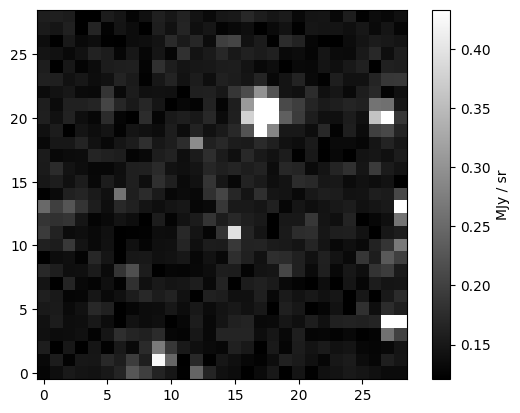

In [13]:
import numpy as np
import matplotlib.pyplot as plt

img = hdul["IMAGE"].data
print(img.shape, np.nanmin(img), np.nanmedian(img), np.nanmax(img))

lo, hi = np.nanpercentile(img, [5, 99])
plt.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
plt.colorbar(label=hdul["IMAGE"].header.get("BUNIT", ""))
plt.show()


In [14]:
flags = hdul["FLAGS"].data
print(flags.shape, np.unique(flags)[:20])

(29, 29) [      0  524288 2097152 2097221]


In [15]:
from astropy.wcs import WCS
w = WCS(hdul["IMAGE"].header)
x, y = w.world_to_pixel(coord)
print(x, y)

14.22261612973784 13.735653533325952


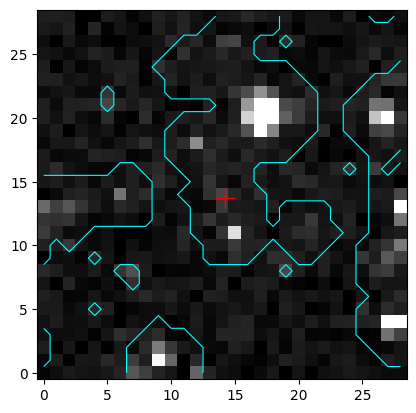

In [16]:
bad = flags != 0
plt.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
plt.plot(x, y, "r+", ms=15)
plt.contour(bad, levels=[0.5], colors="cyan", linewidths=0.8)
plt.show()

In [17]:
h = hdul["IMAGE"].header
print({k: h[k] for k in h if "MJD" in k or "DET" in k})

{'DETECTOR': 3, 'DETCOORD': 'sky', 'MJDREF': 0.0, 'MJD-OBS': 60800.700028461, 'MJD-BEG': 60800.700028461, 'MJD-AVG': 60800.70069465, 'MJD-END': 60800.701360839}


In [18]:
def get_frame(row, coord, size_deg=0.05):
    """Download one cutout and return a dict with:
       time (MJD-AVG), detector, wavelength_um, image, flags, variance, wcs
    """

In [19]:
long = tbl[tbl["em_min"] * 1e6 > 3.8]    # roughly detectors 5 and 6
print(len(long))
frames = [get_frame(r, coord) for r in long[:8]]
frames = [f for f in frames if f is not None]


94


In [20]:
import io, requests
import numpy as np
import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS

def get_frame(row, coord, size_deg=0.05):
    """Download one SPHEREx cutout and return its useful pieces as a dict."""
    # 1. Ask IRSA for just a small square around the target
    url = f"{row['access_url']}?center={coord.ra.deg},{coord.dec.deg}&size={size_deg}"

    try:
        resp = requests.get(url, timeout=120)
        resp.raise_for_status()                       # error out on 4xx/5xx
        hdul = fits.open(io.BytesIO(resp.content))    # open FITS from memory
    except Exception as e:
        print("download failed:", str(e)[:80])
        return None

    try:
        hdr = hdul["IMAGE"].header

        # 2. Where is the target in this particular frame? (sky -> pixel)
        x, y = WCS(hdr).world_to_pixel(coord)

        # 3. Which wavelength does that pixel see? (SPHEREx wavelength
        #    changes across the detector, so it depends on position)
        swcs = WCS(hdr, fobj=hdul, key="W")
        swcs.sip = None
        wave, _ = swcs.pixel_to_world(x, y)

        # 4. Copy the arrays out so they survive after the file is closed
        return {
            "time": hdr["MJD-AVG"],
            "detector": hdr["DETECTOR"],
            "wave_um": wave.to(u.um).value,
            "x": float(x), "y": float(y),
            "image": hdul["IMAGE"].data.copy(),
            "flags": hdul["FLAGS"].data.copy(),
            "variance": hdul["VARIANCE"].data.copy(),
        }
    except Exception as e:
        print("parse failed:", str(e)[:80])
        return None
    finally:
        hdul.close()

In [21]:
long = tbl[tbl["em_min"] * 1e6 > 3.8]
frames = [get_frame(r, coord) for r in long[:8]]
frames = [f for f in frames if f is not None]

for f in frames:
    print(round(f["time"], 2), "D", f["detector"], round(f["wave_um"], 2), "um")

INFO:astropy:
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                


INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]


INFO:astropy:
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                


INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]


INFO:astropy:
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                


INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
download failed: 503

... (2 outputs left out)

INFO:astropy:
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                


INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]


INFO:astropy:
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                


INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
download failed: 503

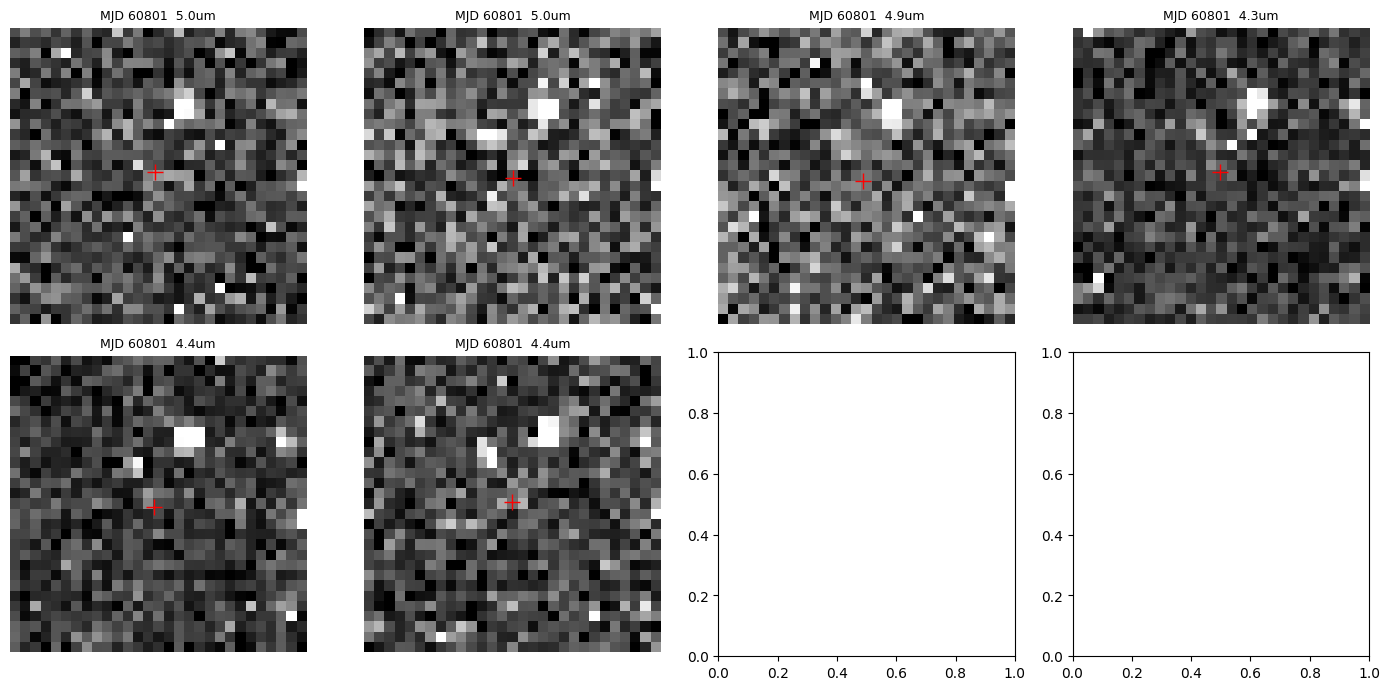

In [22]:
import matplotlib.pyplot as plt

frames.sort(key=lambda f: f["time"])           # time order = video order
fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for ax, f in zip(axs.ravel(), frames):
    img = f["image"]
    lo, hi = np.nanpercentile(img, [5, 99])
    ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.plot(f["x"], f["y"], "r+", ms=12)
    ax.set_title(f"MJD {f['time']:.0f}  {f['wave_um']:.1f}um", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [24]:
import io, time, logging, requests
import numpy as np
import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS

logging.getLogger("astropy").setLevel(logging.ERROR)   # silences the SIP spam

def get_frame(row, coord, size_deg=0.05):
    """Download one SPHEREx cutout and return its useful pieces as a dict."""
    url = f"{row['access_url']}?center={coord.ra.deg},{coord.dec.deg}&size={size_deg}"

    # Download with retries: wait 1s, 2s, 4s, 8s if the server is busy
    resp = None
    for attempt in range(4):
        try:
            r = requests.get(url, timeout=120)
            if r.status_code == 503:
                time.sleep(2 ** attempt)
                continue
            r.raise_for_status()
            resp = r
            break
        except Exception:
            time.sleep(2 ** attempt)

    if resp is None:
        print("download failed after retries")
        return None

    hdul = fits.open(io.BytesIO(resp.content))
    try:
        hdr = hdul["IMAGE"].header
        x, y = WCS(hdr).world_to_pixel(coord)

        swcs = WCS(hdr, fobj=hdul, key="W")
        swcs.sip = None
        wave, _ = swcs.pixel_to_world(x, y)

        return {
            "time": hdr["MJD-AVG"],
            "detector": hdr["DETECTOR"],
            "wave_um": wave.to(u.um).value,
            "x": float(x), "y": float(y),
            "image": hdul["IMAGE"].data.copy(),
            "flags": hdul["FLAGS"].data.copy(),
            "variance": hdul["VARIANCE"].data.copy(),
        }
    except Exception as e:
        print("parse failed:", str(e)[:80])
        return None
    finally:
        hdul.close()

In [25]:
import numpy as np

long = tbl[tbl["em_min"] * 1e6 > 3.8]
t = np.array(long["t_min"])
# split the time span into 6 bins and take up to 3 frames from each
edges = np.linspace(t.min(), t.max(), 7)
picked = []
for a, b in zip(edges[:-1], edges[1:]):
    idx = np.where((t >= a) & (t < b))[0]
    picked += list(idx[:3])
print(len(picked), "frames picked")
frames = [get_frame(long[int(i)], coord) for i in picked]
frames = [f for f in frames if f is not None]

12 frames picked
download failed after retries


In [26]:
def coadd(frames_subset):
    stack = np.array([f["image"] for f in frames_subset], dtype=float)
    return np.nanmedian(stack, axis=0)

In [27]:
frames.sort(key=lambda f: f["time"])
for f in frames:
    print(round(f["time"], 1), "D", f["detector"], round(f["wave_um"], 2), "um")

60800.7 D 6 5.0 um
60800.8 D 6 4.86 um
60986.2 D 5 3.82 um
60986.2 D 5 3.85 um
60986.2 D 5 3.89 um
60989.3 D 6 4.42 um
60989.3 D 6 4.45 um
60989.3 D 6 4.48 um
61151.2 D 6 4.43 um
61151.2 D 6 4.46 um
61151.2 D 6 4.49 um


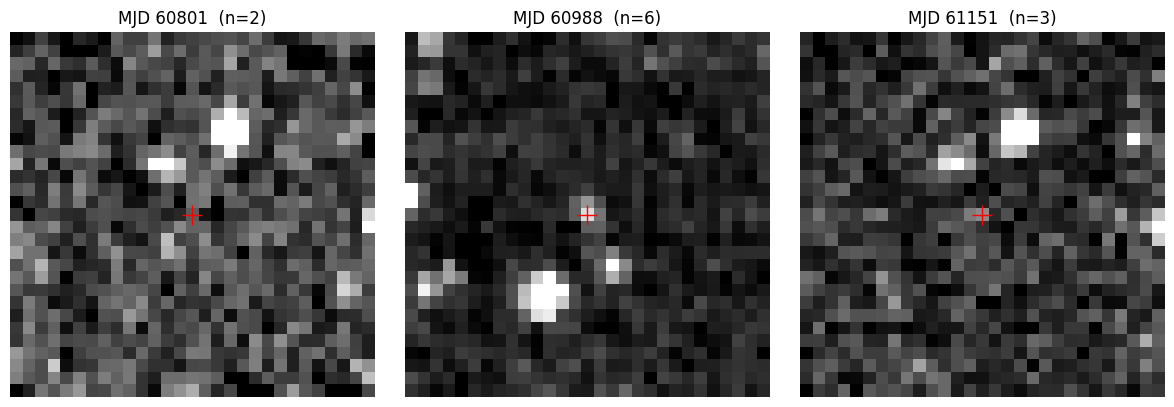

In [28]:
from scipy.ndimage import shift as nd_shift
import matplotlib.pyplot as plt

# 1. group into epochs
epochs, current = [], [frames[0]]
for prev, f in zip(frames[:-1], frames[1:]):
    if f["time"] - prev["time"] > 30:
        epochs.append(current); current = []
    current.append(f)
epochs.append(current)

# 2. align + co-add each epoch
def coadd_aligned(group, target=(14.0, 14.0)):
    stack = []
    for f in group:
        dy = target[1] - f["y"]
        dx = target[0] - f["x"]
        stack.append(nd_shift(f["image"], (dy, dx), order=1, mode="nearest"))
    return np.nanmedian(np.array(stack), axis=0)

# 3. plot one panel per epoch
fig, axs = plt.subplots(1, len(epochs), figsize=(4 * len(epochs), 4))
axs = np.atleast_1d(axs)
for ax, g in zip(axs, epochs):
    img = coadd_aligned(g)
    lo, hi = np.nanpercentile(img, [5, 99])
    ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.plot(14, 14, "r+", ms=14)
    ax.set_title(f"MJD {np.mean([f['time'] for f in g]):.0f}  (n={len(g)})")
    ax.axis("off")
plt.tight_layout(); plt.show()

In [29]:
from concurrent.futures import ThreadPoolExecutor

t = np.array(long["t_min"])
windows = [(60795, 60806), (60980, 60995), (61145, 61158)]   # the 3 visits
sel = [i for i in range(len(long))
       if any(a <= t[i] <= b for a, b in windows)]
print(len(sel), "frames to download")

with ThreadPoolExecutor(max_workers=4) as ex:
    results = list(ex.map(lambda i: get_frame(long[int(i)], coord), sel))

frames = [f for f in results if f is not None]
frames = [f for f in frames if f["detector"] == 6]       # D6 only for now
frames.sort(key=lambda f: f["time"])
print(len(frames), "D6 frames loaded")

63 frames to download
36 D6 frames loaded


shapes: Counter({(29, 29): 35, (30, 29): 1})
keeping 35 of 36 frames, shape (29, 29)
epoch MJD 60800.7 n = 3
epoch MJD 60991.5 n = 18
epoch MJD 61153.8 n = 14


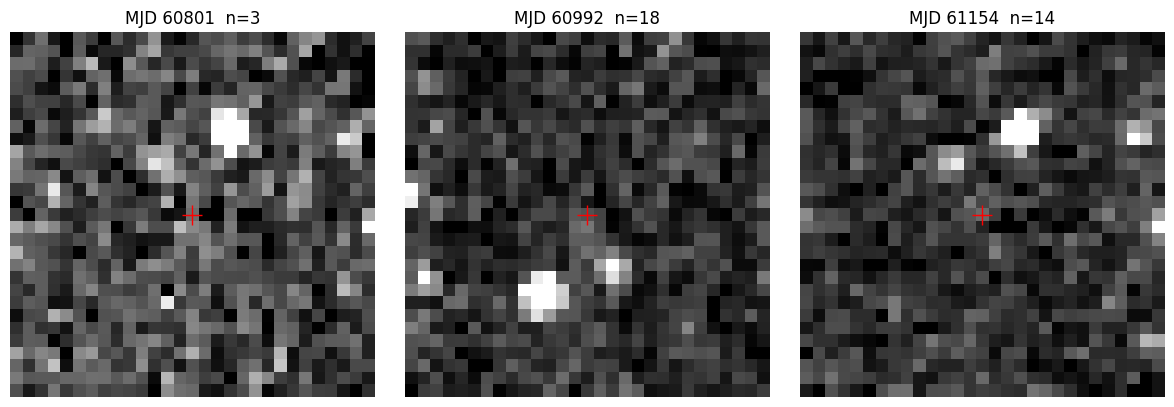

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from scipy.ndimage import shift as nd_shift

# 1. Keep only frames with the most common cutout shape
print("shapes:", Counter(f["image"].shape for f in frames))
common = Counter(f["image"].shape for f in frames).most_common(1)[0][0]
good = [f for f in frames if f["image"].shape == common]
good.sort(key=lambda f: f["time"])
print(f"keeping {len(good)} of {len(frames)} frames, shape {common}")

# 2. Group into epochs (new group when the gap exceeds 30 days)
epochs, current = [], [good[0]]
for prev, f in zip(good[:-1], good[1:]):
    if f["time"] - prev["time"] > 30:
        epochs.append(current)
        current = []
    current.append(f)
epochs.append(current)

for g in epochs:
    print("epoch MJD", round(np.mean([f["time"] for f in g]), 1), "n =", len(g))

# 3. Align each frame on the target, then take the median
cy, cx = (common[0] - 1) / 2, (common[1] - 1) / 2     # centre pixel of the cutout

def coadd_aligned(group):
    stack = []
    for f in group:
        stack.append(nd_shift(f["image"], (cy - f["y"], cx - f["x"]),
                              order=1, mode="nearest"))
    return np.nanmedian(np.array(stack), axis=0)

# 4. One panel per epoch
fig, axs = plt.subplots(1, len(epochs), figsize=(4 * len(epochs), 4))
axs = np.atleast_1d(axs)
for ax, g in zip(axs, epochs):
    img = coadd_aligned(g)
    lo, hi = np.nanpercentile(img, [5, 99])
    ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.plot(cx, cy, "r+", ms=14)
    ax.set_title(f"MJD {np.mean([f['time'] for f in g]):.0f}  n={len(g)}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [33]:
import io, time, logging, requests
import numpy as np
import astropy.units as u
from astropy.io import fits
from astropy.wcs import WCS

logging.getLogger("astropy").setLevel(logging.ERROR)

def get_frame(row, coord, size_deg=0.05):
    url = f"{row['access_url']}?center={coord.ra.deg},{coord.dec.deg}&size={size_deg}"

    resp = None
    for attempt in range(4):
        try:
            r = requests.get(url, timeout=120)
            if r.status_code == 503:
                time.sleep(2 ** attempt)
                continue
            r.raise_for_status()
            resp = r
            break
        except Exception:
            time.sleep(2 ** attempt)

    if resp is None:
        print("download failed after retries")
        return None

    hdul = fits.open(io.BytesIO(resp.content))
    try:
        hdr = hdul["IMAGE"].header
        x, y = WCS(hdr).world_to_pixel(coord)

        swcs = WCS(hdr, fobj=hdul, key="W")
        swcs.sip = None
        wave, _ = swcs.pixel_to_world(x, y)

        return {
            "time": hdr["MJD-AVG"],
            "detector": hdr["DETECTOR"],
            "wave_um": wave.to(u.um).value,
            "x": float(x), "y": float(y),
            "image": hdul["IMAGE"].data.copy(),
            "flags": hdul["FLAGS"].data.copy(),
            "variance": hdul["VARIANCE"].data.copy(),
            "header": hdr.copy(),          # <-- NEW LINE
        }
    except Exception as e:
        print("parse failed:", str(e)[:80])
        return None
    finally:
        hdul.close()

In [34]:
import numpy as np
from concurrent.futures import ThreadPoolExecutor

t = np.array(long["t_min"])
windows = [(60795, 60806), (60980, 60995), (61145, 61158)]   # the 3 visits
sel = [i for i in range(len(long))
       if any(a <= t[i] <= b for a, b in windows)]
print(len(sel), "frames to download")

with ThreadPoolExecutor(max_workers=4) as ex:
    results = list(ex.map(lambda i: get_frame(long[int(i)], coord), sel))

frames = [f for f in results if f is not None]
frames = [f for f in frames if f["detector"] == 6]       # D6 only
frames.sort(key=lambda f: f["time"])
print(len(frames), "D6 frames loaded")
print("has header:", all("header" in f for f in frames))

63 frames to download
download failed after retries
download failed after retries
download failed after retries
34 D6 frames loaded
has header: True


In [35]:
!pip install reproject

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 14.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.0 MB/s  0:00:00
  Created wheel for pims: filename=pims-0.7-py3-none-any.whl size=84644 sha256=1c53d184870c0b942a4cb496e498fc78f7ba6cb6011f68adac8e65631bdd14fa
  Stored in directory: /root/.cache/pip/wheels/9b/9e/a8/a0f41cf12a4a7b98a501ad8590595e2071a946d2fd33b0eb60
Successfully built pims
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [reproject]


In [37]:
import numpy as np
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.time import Time
from astroquery.ipac.irsa import Irsa
from concurrent.futures import ThreadPoolExecutor

# --- move the challenge position forward to SPHEREx's epoch ---
EPOCH0  = 2010.5      # ASSUMED epoch of the challenge coordinates: check this
PM_RA   = -8.1        # arcsec/yr (includes cos(dec)): check in SIMBAD
PM_DEC  = +0.7        # arcsec/yr: check in SIMBAD
ra0, dec0 = 133.795129, -7.245147

year_now = Time(61000, format="mjd").decimalyear      # middle of the SPHEREx data
dt = year_now - EPOCH0
ra1  = ra0 + (PM_RA * dt / 3600) / np.cos(np.radians(dec0))
dec1 = dec0 + (PM_DEC * dt / 3600)
target = SkyCoord(ra1 * u.deg, dec1 * u.deg)
print("predicted position:", ra1, dec1, " (moved", round(dt, 1), "yr)")

# --- search around the predicted position ---
r = Irsa.query_sia(pos=(target, 0.05 * u.deg), collection="spherex_dr1")
tbl = r.to_table() if hasattr(r, "to_table") else r
tbl.sort("t_min")
long = tbl[tbl["em_min"] * 1e6 > 3.8]
print(len(tbl), "images,", len(long), "at long wavelengths")

# --- download WIDER cutouts (0.1 deg ~ 58 pixels) ---
t = np.array(long["t_min"])
windows = [(60795, 60806), (60980, 60995), (61145, 61158)]
sel = [i for i in range(len(long)) if any(a <= t[i] <= b for a, b in windows)]
print(len(sel), "frames to download")

with ThreadPoolExecutor(max_workers=3) as ex:
    results = list(ex.map(lambda i: get_frame(long[int(i)], target, size_deg=0.1), sel))

frames = [f for f in results if f is not None and f["detector"] == 6]
frames.sort(key=lambda f: f["time"])
print(len(frames), "D6 frames loaded")

coord = target      # the reproject cell uses `coord`

predicted position: 133.76022807803596 -7.24215495281583  (moved 15.4 yr)
263 images, 94 at long wavelengths
63 frames to download
download failed after retries
36 D6 frames loaded


keeping 32 of 36 frames, shape (58, 58)


epoch MJD 60800.8 n = 2
epoch MJD 60991.5 n = 18
epoch MJD 61153.7 n = 12


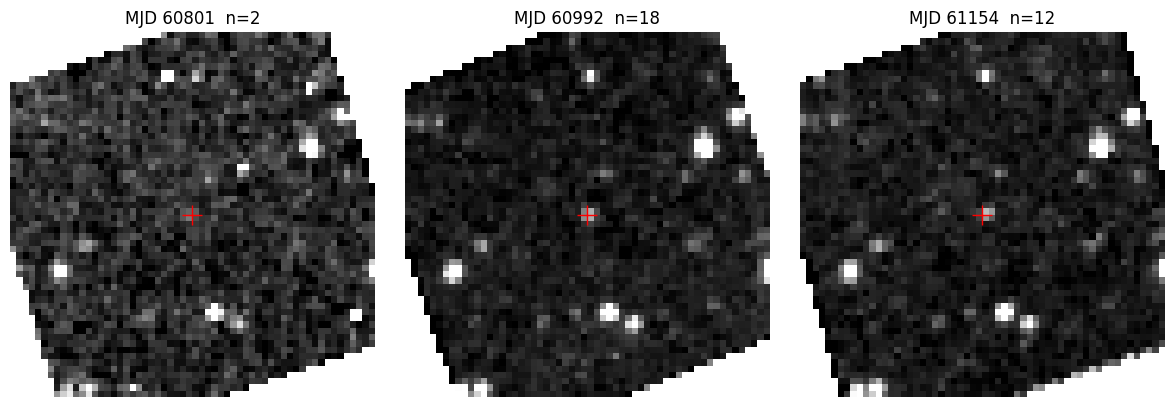

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from astropy.wcs import WCS
from astropy.stats import sigma_clip
from reproject import reproject_interp

# keep frames with the usual cutout shape, sorted by time
common = Counter(f["image"].shape for f in frames).most_common(1)[0][0]
good = sorted([f for f in frames if f["image"].shape == common],
              key=lambda f: f["time"])
print(f"keeping {len(good)} of {len(frames)} frames, shape {common}")

# one shared north-up grid centred on the target
N = common[0]
pix_deg = 6.2 / 3600          # approx SPHEREx pixel size
tw = WCS(naxis=2)
tw.wcs.ctype = ["RA---TAN", "DEC--TAN"]
tw.wcs.crval = [coord.ra.deg, coord.dec.deg]
tw.wcs.crpix = [(N + 1) / 2, (N + 1) / 2]
tw.wcs.cdelt = [-pix_deg, pix_deg]

# resample every frame onto that grid
for f in good:
    f["aligned"], _ = reproject_interp((f["image"], WCS(f["header"])),
                                       tw, shape_out=(N, N))

# group into epochs (new group when the gap exceeds 30 days)
epochs, cur = [], [good[0]]
for a, b in zip(good[:-1], good[1:]):
    if b["time"] - a["time"] > 30:
        epochs.append(cur)
        cur = []
    cur.append(b)
epochs.append(cur)
for g in epochs:
    print("epoch MJD", round(np.mean([f["time"] for f in g]), 1), "n =", len(g))

# co-add with sigma clipping, then plot
fig, axs = plt.subplots(1, len(epochs), figsize=(4 * len(epochs), 4))
axs = np.atleast_1d(axs)
for ax, g in zip(axs, epochs):
    stack = np.array([f["aligned"] for f in g])
    img = sigma_clip(stack, sigma=3, axis=0, masked=True).mean(axis=0).filled(np.nan)
    lo, hi = np.nanpercentile(img, [5, 99])
    ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.plot((N - 1) / 2, (N - 1) / 2, "r+", ms=14)
    ax.set_title(f"MJD {np.mean([f['time'] for f in g]):.0f}  n={len(g)}")
    ax.axis("off")
plt.tight_layout()
plt.show()

MJD 60801 n=2: peak at x=28, y=29 (offset -0.5, +0.5), SNR = 2.0
MJD 60992 n=18: peak at x=29, y=28 (offset +0.5, -0.5), SNR = 6.9
MJD 61154 n=12: peak at x=29, y=29 (offset +0.5, +0.5), SNR = 6.6


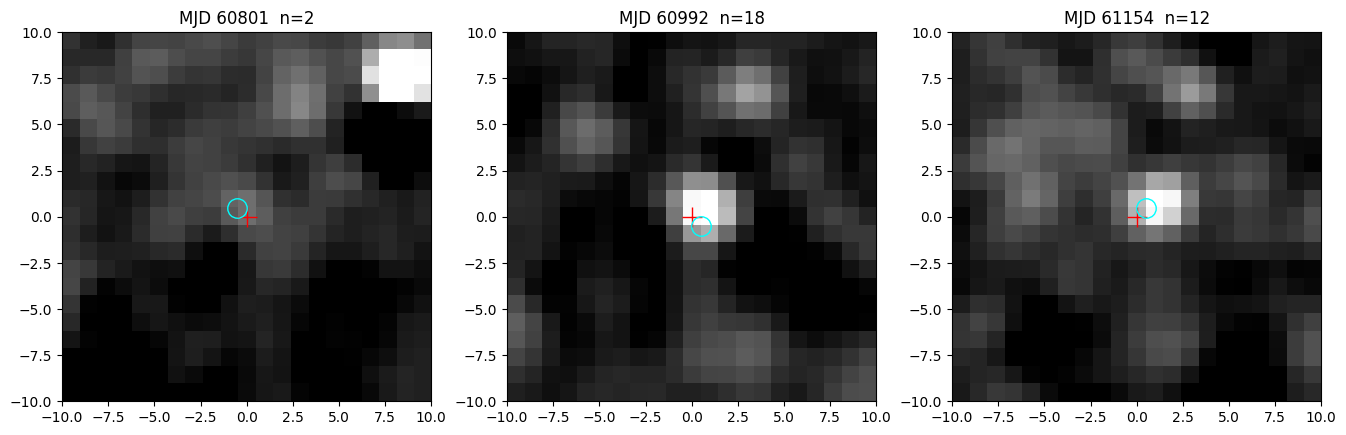

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from astropy.stats import sigma_clip

c = (N - 1) / 2
R = 10                       # half-width of the zoom, in pixels
yy, xx = np.mgrid[0:N, 0:N]
near = (xx - c) ** 2 + (yy - c) ** 2 <= 4 ** 2       # within 4 px of the target

fig, axs = plt.subplots(1, len(epochs), figsize=(4.5 * len(epochs), 4.5))
axs = np.atleast_1d(axs)
for ax, g in zip(axs, epochs):
    stack = np.array([f["aligned"] for f in g])
    img = sigma_clip(stack, sigma=3, axis=0, masked=True).mean(axis=0).filled(np.nan)
    sm = gaussian_filter(np.nan_to_num(img, nan=np.nanmedian(img)), 1.0)

    # noise: spread of the smoothed image, measured away from the centre
    far = ~near & np.isfinite(img)
    bkg, sig = np.median(sm[far]), 1.4826 * np.median(np.abs(sm[far] - np.median(sm[far])))

    # brightest smoothed pixel near the target
    cand = np.where(near, sm, -np.inf)
    py, px = np.unravel_index(np.argmax(cand), cand.shape)
    snr = (sm[py, px] - bkg) / sig
    print(f"MJD {np.mean([f['time'] for f in g]):.0f} n={len(g)}: "
          f"peak at x={px}, y={py} (offset {px-c:+.1f}, {py-c:+.1f}), SNR = {snr:.1f}")

    sl = (slice(int(c) - R, int(c) + R + 1), slice(int(c) - R, int(c) + R + 1))
    ax.imshow(sm[sl], origin="lower", cmap="gray",
              vmin=bkg - sig, vmax=bkg + 6 * sig,
              extent=[-R, R, -R, R])
    ax.plot(0, 0, "r+", ms=14)
    ax.plot(px - c, py - c, "o", mfc="none", mec="cyan", ms=14)
    ax.set_title(f"MJD {np.mean([f['time'] for f in g]):.0f}  n={len(g)}")
plt.tight_layout(); plt.show()

In [40]:
import numpy as np
from astropy.stats import sigma_clip
from scipy.ndimage import gaussian_filter

c = (N - 1) / 2
rng = np.random.default_rng(0)
PIX = 6.2   # arcsec per pixel (approx)

def coadd(frs):
    stack = np.array([f["aligned"] for f in frs])
    return sigma_clip(stack, sigma=3, axis=0, masked=True).mean(axis=0).filled(np.nan)

def snr_at(img, px, py):
    sm = gaussian_filter(np.nan_to_num(img, nan=np.nanmedian(img)), 1.0)
    yy, xx = np.mgrid[0:N, 0:N]
    far = ((xx - c) ** 2 + (yy - c) ** 2 > 16) & np.isfinite(img)
    bkg = np.median(sm[far])
    sig = 1.4826 * np.median(np.abs(sm[far] - bkg))
    return (sm[py, px] - bkg) / sig

def centroid(img, px, py, h=2):
    cut = img[py-h:py+h+1, px-h:px+h+1].copy()
    cut = np.nan_to_num(cut - np.nanmedian(img))
    cut[cut < 0] = 0
    ys, xs = np.mgrid[py-h:py+h+1, px-h:px+h+1]
    return (xs * cut).sum() / cut.sum(), (ys * cut).sum() / cut.sum()

for g in epochs[1:]:                      # epochs 2 and 3 only
    full = coadd(g)
    sm = gaussian_filter(np.nan_to_num(full, nan=np.nanmedian(full)), 1.0)
    yy, xx = np.mgrid[0:N, 0:N]
    near = (xx - c) ** 2 + (yy - c) ** 2 <= 16
    py, px = np.unravel_index(np.argmax(np.where(near, sm, -np.inf)), sm.shape)

    half_a, half_b = g[0::2], g[1::2]
    print(f"\nMJD {np.mean([f['time'] for f in g]):.0f}  n={len(g)}")
    print("  SNR full:", round(snr_at(full, px, py), 1),
          "| half A:", round(snr_at(coadd(half_a), px, py), 1),
          "| half B:", round(snr_at(coadd(half_b), px, py), 1))

    cents = []
    for _ in range(200):                  # bootstrap over frames
        pick = [g[i] for i in rng.integers(0, len(g), len(g))]
        cents.append(centroid(coadd(pick), px, py))
    cents = np.array(cents)
    mx, my = cents.mean(axis=0); sx, sy = cents.std(axis=0)
    print(f"  centroid offset from target: x = {(mx-c):+.2f} ± {sx:.2f} px, "
          f"y = {(my-c):+.2f} ± {sy:.2f} px")


MJD 60992  n=18
  SNR full: 6.9 | half A: 6.2 | half B: 5.3
  centroid offset from target: x = +0.41 ± 0.38 px, y = -0.06 ± 0.33 px

MJD 61154  n=12
  SNR full: 6.6 | half A: 3.6 | half B: 2.2
  centroid offset from target: x = +0.64 ± 0.11 px, y = +0.29 ± 0.09 px


In [41]:
import numpy as np
from collections import defaultdict
from astropy.wcs import WCS
from astropy.stats import sigma_clip
from reproject import reproject_interp
from concurrent.futures import ThreadPoolExecutor

# detector wavelength bands (um). D3-D6 are from IRSA docs; D1, D2 are from memory
BANDS = {1: (0.75, 1.09), 2: (1.10, 1.62), 3: (1.63, 2.41),
         4: (2.42, 3.82), 5: (3.83, 4.41)}
t = np.array(tbl["t_min"]); wl = np.array(tbl["em_min"]) * 1e6
windows = [(60795, 60806), (60980, 60995), (61145, 61158)]
in_win = np.array([any(a <= x <= b for a, b in windows) for x in t])

rows = []
for d, (lo, hi) in BANDS.items():
    idx = np.where(in_win & (wl >= lo) & (wl <= hi))[0]
    if len(idx):
        keep = idx[np.linspace(0, len(idx) - 1, min(8, len(idx))).astype(int)]
        rows += [int(i) for i in keep]
print(len(rows), "frames to download")

with ThreadPoolExecutor(max_workers=3) as ex:
    res = list(ex.map(lambda i: get_frame(tbl[i], coord, size_deg=0.1), rows))
by_det = defaultdict(list)
for f in [r for r in res if r is not None] + frames:    # frames = your D6 set
    if f["image"].shape == (N, N):
        by_det[f["detector"]].append(f)

c = (N - 1) / 2
yy, xx = np.mgrid[0:N, 0:N]
rr = np.hypot(xx - c, yy - c)
aper, ann = rr <= 2.5, (rr >= 6) & (rr <= 12)

print("\ndet  n_frames  SNR at target")
for d in sorted(by_det):
    g = by_det[d]
    stack = np.array([reproject_interp((f["image"], WCS(f["header"])), tw,
                                       shape_out=(N, N))[0] for f in g])
    img = sigma_clip(stack, sigma=3, axis=0, masked=True).mean(axis=0).filled(np.nan)
    bkg_pix = img[ann & np.isfinite(img)]
    med = np.median(bkg_pix)
    sig = 1.4826 * np.median(np.abs(bkg_pix - med))
    excess = np.nanmean(img[aper]) - med
    snr = excess / (sig / np.sqrt(aper.sum()))
    print(f" D{d}   {len(g):3d}      {snr:6.1f}")

24 frames to download
download failed after retries

det  n_frames  SNR at target
 D4     2       209.0
 D5     1         5.1
 D6    32        15.2


images per detector in the 3 visits: {1: 10, 2: 27, 3: 37, 4: 11, 5: 27, 6: 36}
50 frames to download
download failed after retries

det  n_frames   SNR at target (empirical noise)
 D1     3         0.5
 D2     0      too few frames
 D3     1      too few frames
 D4     8         3.0
 D5     0      too few frames
 D6    10         6.2


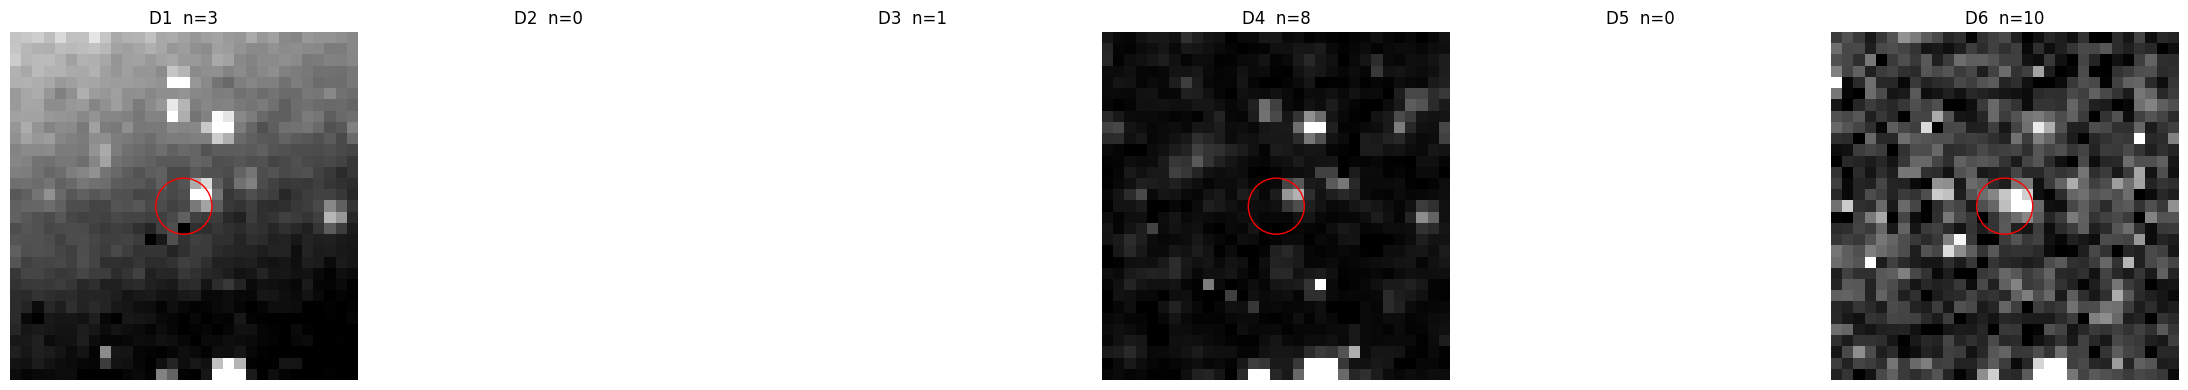

In [42]:
import re
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from astropy.wcs import WCS
from astropy.stats import sigma_clip
from reproject import reproject_interp
from concurrent.futures import ThreadPoolExecutor

def det_from_url(u):
    m = re.search(r"_\d+D(\d)_spx", str(u))
    return int(m.group(1)) if m else None

t = np.array(tbl["t_min"])
dets = np.array([det_from_url(u) for u in tbl["access_url"]])
windows = [(60795, 60806), (60980, 60995), (61145, 61158)]
in_win = np.array([any(a <= x <= b for a, b in windows) for x in t])
print("images per detector in the 3 visits:",
      {d: int((in_win & (dets == d)).sum()) for d in range(1, 7)})

# up to 10 frames per detector, spread through the list (D1-D5 downloaded; D6 reused)
rows = []
for d in range(1, 6):
    idx = np.where(in_win & (dets == d))[0]
    if len(idx):
        keep = idx[np.linspace(0, len(idx) - 1, min(10, len(idx))).astype(int)]
        rows += [int(i) for i in keep]
print(len(rows), "frames to download")

with ThreadPoolExecutor(max_workers=3) as ex:
    res = list(ex.map(lambda i: get_frame(tbl[i], coord, size_deg=0.1), rows))

by_det = defaultdict(list)
for f in [r for r in res if r is not None]:
    if f["image"].shape == (N, N):
        by_det[f["detector"]].append(f)
d6 = [f for f in frames if f["image"].shape == (N, N)]
by_det[6] = [d6[i] for i in np.linspace(0, len(d6) - 1, min(10, len(d6))).astype(int)]

c = (N - 1) / 2
yy, xx = np.mgrid[0:N, 0:N]
R_AP = 2.5

def aper_mean(img, cx, cy):
    m = np.hypot(xx - cx, yy - cy) <= R_AP
    v = img[m]
    return np.nanmean(v) if np.isfinite(v).sum() > 0.8 * m.sum() else np.nan

fig, axs = plt.subplots(1, 6, figsize=(22, 4))
print("\ndet  n_frames   SNR at target (empirical noise)")
for d, ax in zip(range(1, 7), axs):
    g = by_det.get(d, [])
    ax.set_title(f"D{d}  n={len(g)}"); ax.axis("off")
    if len(g) < 2:
        print(f" D{d}   {len(g):3d}      too few frames"); continue
    stack = np.array([reproject_interp((f["image"], WCS(f["header"])), tw,
                                       shape_out=(N, N))[0] for f in g])
    img = sigma_clip(stack, sigma=3, axis=0, masked=True).mean(axis=0).filled(np.nan)

    # empirical noise: same aperture at many other positions
    vals = [aper_mean(img, x, y)
            for x in range(8, N - 8, 3) for y in range(8, N - 8, 3)
            if np.hypot(x - c, y - c) > 8]
    vals = np.array([v for v in vals if np.isfinite(v)])
    med = np.median(vals); sig = 1.4826 * np.median(np.abs(vals - med))
    snr = (aper_mean(img, c, c) - med) / sig
    print(f" D{d}   {len(g):3d}      {snr:6.1f}")

    sl = slice(int(c) - 15, int(c) + 16)
    lo, hi = np.nanpercentile(img[sl, sl], [5, 99])
    ax.imshow(img[sl, sl], origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.add_patch(plt.Circle((15, 15), R_AP, fill=False, ec="red", lw=1))
plt.tight_layout(); plt.show()

In [43]:
from collections import Counter
ok = [r for r in res if r is not None]
print("downloaded:", len(ok), "of", len(res), "(None =", len(res) - len(ok), ")")
print("shapes by detector:")
for d in range(1, 6):
    print(f"  D{d}:", Counter(r["image"].shape for r in ok if r["detector"] == d))
print("N expected:", (N, N))

downloaded: 49 of 50 (None = 1 )
shapes by detector:
  D1: Counter({(59, 58): 7, (58, 58): 3})
  D2: Counter({(59, 59): 10})
  D3: Counter({(59, 58): 9, (58, 58): 1})
  D4: Counter({(58, 58): 8, (58, 59): 1})
  D5: Counter({(59, 59): 8, (58, 59): 2})
N expected: (58, 58)


det  n_frames  mean_wave_um   SNR   excess(MJy/sr)
 D1    10       0.89       10.7     0.0760
 D2    10       1.36        5.2     0.0634
 D3    10       2.05        4.4     0.0414
 D4     9       2.98        3.0     0.0200
 D5    10       4.12        6.8     0.0391
 D6    10       4.72        5.0     0.0377


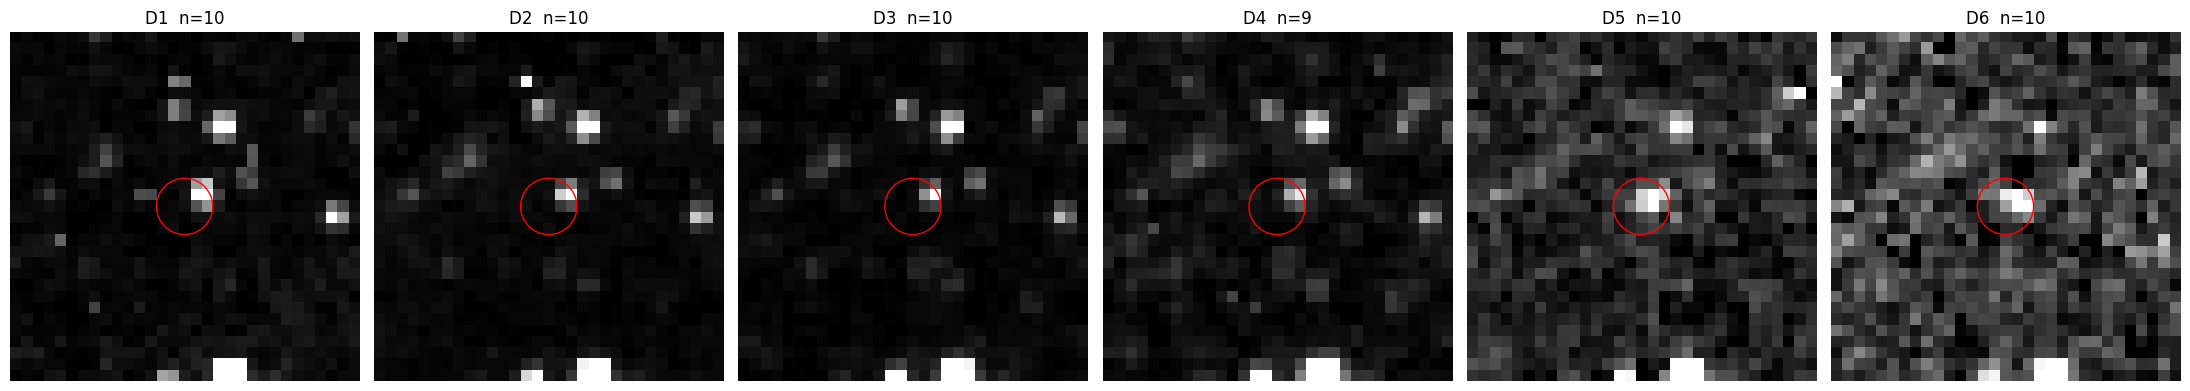

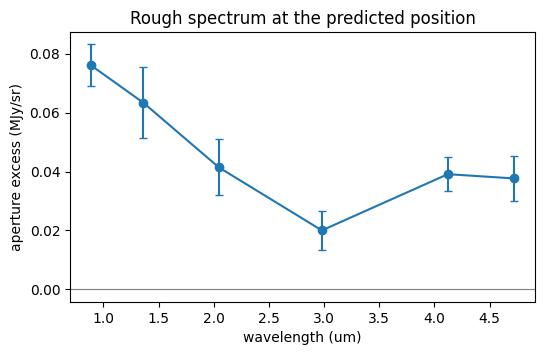

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from astropy.wcs import WCS
from astropy.stats import sigma_clip
from reproject import reproject_interp

# use every downloaded frame, no shape filter
by_det = defaultdict(list)
for f in [r for r in res if r is not None]:
    by_det[f["detector"]].append(f)
d6 = frames                                    # your D6 set from earlier
by_det[6] = [d6[i] for i in np.linspace(0, len(d6) - 1, min(10, len(d6))).astype(int)]

c = (N - 1) / 2
yy, xx = np.mgrid[0:N, 0:N]
R_AP = 2.5

def aper_mean(img, cx, cy):
    m = np.hypot(xx - cx, yy - cy) <= R_AP
    v = img[m]
    return np.nanmean(v) if np.isfinite(v).sum() > 0.8 * m.sum() else np.nan

fig, axs = plt.subplots(1, 6, figsize=(22, 4))
spec = []      # (mean wavelength, excess, noise)
print("det  n_frames  mean_wave_um   SNR   excess(MJy/sr)")
for d, ax in zip(range(1, 7), axs):
    g = by_det.get(d, [])
    ax.set_title(f"D{d}  n={len(g)}"); ax.axis("off")
    if len(g) < 2:
        print(f" D{d}   {len(g):3d}      too few frames"); continue
    stack = np.array([reproject_interp((f["image"], WCS(f["header"])), tw,
                                       shape_out=(N, N))[0] for f in g])
    img = sigma_clip(stack, sigma=3, axis=0, masked=True).mean(axis=0).filled(np.nan)

    vals = [aper_mean(img, x, y)
            for x in range(8, N - 8, 3) for y in range(8, N - 8, 3)
            if np.hypot(x - c, y - c) > 8]
    vals = np.array([v for v in vals if np.isfinite(v)])
    med = np.median(vals); sig = 1.4826 * np.median(np.abs(vals - med))
    excess = aper_mean(img, c, c) - med
    wave = np.mean([f["wave_um"] for f in g])
    print(f" D{d}   {len(g):3d}      {wave:5.2f}      {excess/sig:5.1f}   {excess:8.4f}")
    spec.append((wave, excess, sig))

    sl = slice(int(c) - 15, int(c) + 16)
    lo, hi = np.nanpercentile(img[sl, sl], [5, 99])
    ax.imshow(img[sl, sl], origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.add_patch(plt.Circle((15, 15), R_AP, fill=False, ec="red", lw=1))
plt.tight_layout(); plt.show()

# rough spectrum at the target
if spec:
    w, e, s = np.array(spec).T
    plt.figure(figsize=(6, 3.5))
    plt.errorbar(w, e, yerr=s, fmt="o-", capsize=3)
    plt.axhline(0, color="gray", lw=0.8)
    plt.xlabel("wavelength (um)"); plt.ylabel("aperture excess (MJy/sr)")
    plt.title("Rough spectrum at the predicted position"); plt.show()

In [45]:
import numpy as np
from scipy.ndimage import gaussian_filter
from astropy.wcs import WCS
from astropy.stats import sigma_clip
from reproject import reproject_interp

PIX = 6.2    # arcsec per pixel (approx)
c = (N - 1) / 2
yy, xx = np.mgrid[0:N, 0:N]

def coadd_frames(frs):
    stack = np.array([reproject_interp((f["image"], WCS(f["header"])), tw,
                                       shape_out=(N, N))[0] for f in frs])
    return sigma_clip(stack, sigma=3, axis=0, masked=True).mean(axis=0).filled(np.nan)

def peak_and_centroid(img, radius=5, h=2):
    sm = gaussian_filter(np.nan_to_num(img, nan=np.nanmedian(img)), 1.0)
    near = np.hypot(xx - c, yy - c) <= radius
    py, px = np.unravel_index(np.argmax(np.where(near, sm, -np.inf)), sm.shape)
    cut = np.nan_to_num(img[py-h:py+h+1, px-h:px+h+1] - np.nanmedian(img))
    cut[cut < 0] = 0
    ys, xs = np.mgrid[py-h:py+h+1, px-h:px+h+1]
    cx, cy = (xs * cut).sum() / cut.sum(), (ys * cut).sum() / cut.sum()
    return cx - c, cy - c                       # offset from target, in pixels

print("PER DETECTOR (offset from predicted position; +x = west, +y = north)")
for d in range(1, 7):
    g = by_det.get(d, [])
    if len(g) < 2: continue
    dx, dy = peak_and_centroid(coadd_frames(g))
    print(f" D{d}: dx={dx:+.2f} px, dy={dy:+.2f} px   ({dx*PIX:+.1f}\", {dy*PIX:+.1f}\")")

# D5+D6 per epoch
print("\nD5+D6 BY EPOCH")
long_frames = sorted(by_det[5] + by_det[6], key=lambda f: f["time"])
edges = [(60795, 60806), (60980, 60995), (61145, 61158)]
for a, b in edges:
    g = [f for f in long_frames if a <= f["time"] <= b]
    if len(g) < 2:
        print(f" MJD {a}-{b}: only {len(g)} frames"); continue
    dx, dy = peak_and_centroid(coadd_frames(g))
    print(f" MJD ~{np.mean([f['time'] for f in g]):.0f}  n={len(g)}: "
          f"dx={dx:+.2f} px, dy={dy:+.2f} px")

PER DETECTOR (offset from predicted position; +x = west, +y = north)


 D1: dx=+1.21 px, dy=+0.61 px   (+7.5", +3.8")
 D2: dx=+1.27 px, dy=+0.60 px   (+7.9", +3.7")
 D3: dx=+1.21 px, dy=+0.58 px   (+7.5", +3.6")
 D4: dx=+1.22 px, dy=+0.51 px   (+7.6", +3.2")
 D5: dx=+0.59 px, dy=+0.09 px   (+3.7", +0.6")
 D6: dx=+0.52 px, dy=-0.06 px   (+3.2", -0.4")

D5+D6 BY EPOCH
 MJD ~60801  n=4: dx=-5.25 px, dy=+2.29 px
 MJD ~60989  n=12: dx=+0.66 px, dy=-0.20 px
 MJD ~61154  n=4: dx=+0.20 px, dy=+0.18 px


In [46]:
import numpy as np
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.time import Time

def propagate(ra_deg, dec_deg, pmra_masyr, pmdec_masyr, epoch_year, to_mjd=61000):
    """Move a catalog position forward to a given date. pmra is the cos(dec)-corrected value."""
    c0 = SkyCoord(ra=ra_deg*u.deg, dec=dec_deg*u.deg,
                  pm_ra_cosdec=pmra_masyr*u.mas/u.yr,
                  pm_dec=pmdec_masyr*u.mas/u.yr,
                  obstime=Time(epoch_year, format="jyear"))
    return c0.apply_space_motion(new_obstime=Time(to_mjd, format="mjd"))

# Barnard's Star: values from memory (J2000 position, Gaia-like proper motion). VERIFY in SIMBAD.
barnard = propagate(269.4521, 4.6934, -798.6, 10328.1, epoch_year=2000.0)
print(barnard.ra.deg, barnard.dec.deg)

269.44633729948066 4.767669732725732


/usr/local/lib/python3.13/dist-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 1 of "distance overridden (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


257 images cover Barnard's Star; MJD 60902.864715 to 61165.082972
download failed after retries
39 frames downloaded
36 of 36 frames have a clear star
measured motion: +6.7 arcsec/yr north, -0.4 arcsec/yr east
expected (from memory, please verify in SIMBAD): about +10.3 north, -0.8 east


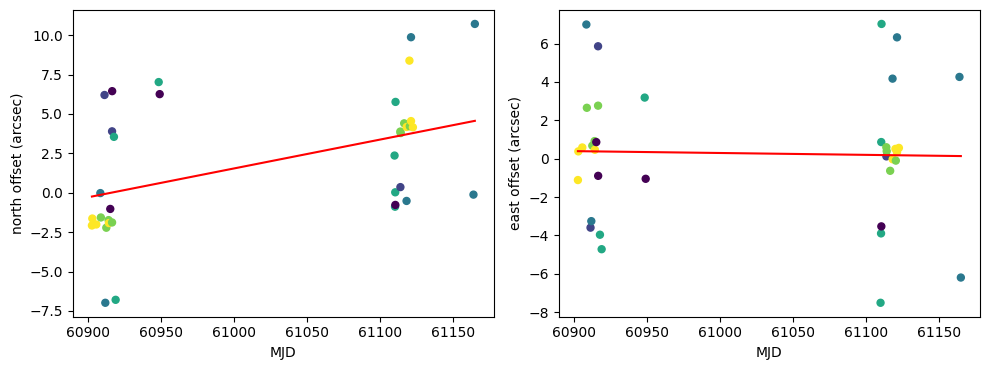

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astroquery.ipac.irsa import Irsa
from reproject import reproject_interp
from scipy.ndimage import gaussian_filter
from concurrent.futures import ThreadPoolExecutor

target_b = SkyCoord(barnard.ra.deg * u.deg, barnard.dec.deg * u.deg)

# 1. find images
r = Irsa.query_sia(pos=(target_b, 0.05 * u.deg), collection="spherex_dr1")
tb = r.to_table() if hasattr(r, "to_table") else r
tb.sort("t_min")
print(len(tb), "images cover Barnard's Star; MJD", tb["t_min"][0], "to", tb["t_min"][-1])

# 2. pick up to 40 frames spread evenly in time
pick = np.linspace(0, len(tb) - 1, min(40, len(tb))).astype(int)
with ThreadPoolExecutor(max_workers=3) as ex:
    res_b = list(ex.map(lambda i: get_frame(tb[int(i)], target_b, size_deg=0.1), pick))
fb = [f for f in res_b if f is not None]
print(len(fb), "frames downloaded")

# 3. common north-up grid centred on the predicted position
NB, PIX = 58, 6.2
tw_b = WCS(naxis=2)
tw_b.wcs.ctype = ["RA---TAN", "DEC--TAN"]
tw_b.wcs.crval = [target_b.ra.deg, target_b.dec.deg]
tw_b.wcs.crpix = [(NB + 1) / 2, (NB + 1) / 2]
tw_b.wcs.cdelt = [-PIX / 3600, PIX / 3600]
cb = (NB - 1) / 2
yy, xx = np.mgrid[0:NB, 0:NB]

# 4. measure the star in each frame
rows = []
for f in fb:
    img = reproject_interp((f["image"], WCS(f["header"])), tw_b, shape_out=(NB, NB))[0]
    sm = gaussian_filter(np.nan_to_num(img, nan=np.nanmedian(img)), 1.0)
    near = np.hypot(xx - cb, yy - cb) <= 8
    py, px = np.unravel_index(np.argmax(np.where(near, sm, -np.inf)), sm.shape)
    h = 2
    cut = np.nan_to_num(img[py-h:py+h+1, px-h:px+h+1] - np.nanmedian(img))
    cut[cut < 0] = 0
    if cut.sum() <= 0:
        continue
    ys, xs = np.mgrid[py-h:py+h+1, px-h:px+h+1]
    cx, cy = (xs * cut).sum() / cut.sum(), (ys * cut).sum() / cut.sum()
    snr = (sm[py, px] - np.median(sm)) / (1.4826 * np.median(np.abs(sm - np.median(sm))))
    rows.append((f["time"], -(cx - cb) * PIX, (cy - cb) * PIX, snr, f["detector"]))

rows = np.array(rows)
good = rows[rows[:, 3] > 8]                       # keep clear detections only
print(len(good), "of", len(rows), "frames have a clear star")

# 5. straight-line fit: arcsec offset versus years
yrs = (good[:, 0] - 61000) / 365.25
east = np.polyfit(yrs, good[:, 1], 1)
north = np.polyfit(yrs, good[:, 2], 1)
print(f"measured motion: {north[0]:+.1f} arcsec/yr north, {east[0]:+.1f} arcsec/yr east")
print("expected (from memory, please verify in SIMBAD): about +10.3 north, -0.8 east")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, col, fit, lab in [(ax[0], 2, north, "north offset (arcsec)"),
                         (ax[1], 1, east, "east offset (arcsec)")]:
    a.scatter(good[:, 0], good[:, col], c=good[:, 4], cmap="viridis", s=25)
    a.plot(good[:, 0], np.polyval(fit, yrs), "r-")
    a.set_xlabel("MJD"); a.set_ylabel(lab)
plt.tight_layout(); plt.show()

In [49]:
import numpy as np
from scipy.stats import theilslopes
from scipy.ndimage import gaussian_filter
from astropy.wcs import WCS
from reproject import reproject_interp

def measure(f, radius=3, h=2):
    img = reproject_interp((f["image"], WCS(f["header"])), tw_b, shape_out=(NB, NB))[0]
    sm = gaussian_filter(np.nan_to_num(img, nan=np.nanmedian(img)), 1.0)
    near = np.hypot(xx - cb, yy - cb) <= radius
    py, px = np.unravel_index(np.argmax(np.where(near, sm, -np.inf)), sm.shape)
    cut = np.nan_to_num(img[py-h:py+h+1, px-h:px+h+1] - np.nanmedian(img))
    cut[cut < 0] = 0
    if cut.sum() <= 0:
        return None
    ys, xs = np.mgrid[py-h:py+h+1, px-h:px+h+1]
    cx, cy = (xs * cut).sum() / cut.sum(), (ys * cut).sum() / cut.sum()
    return f["time"], -(cx - cb) * PIX, (cy - cb) * PIX, f["detector"]

rows = np.array([m for m in (measure(f) for f in fb) if m is not None])
yrs = (rows[:, 0] - 61000) / 365.25
early = rows[:, 0] < 61050

print("det  n_early n_late  north_early  north_late   rate (arcsec/yr)")
for d in range(1, 7):
    m = rows[:, 3] == d
    e, l = m & early, m & ~early
    if e.sum() >= 2 and l.sum() >= 2:
        ne, nl = np.median(rows[e, 2]), np.median(rows[l, 2])
        dt = (np.median(rows[l, 0]) - np.median(rows[e, 0])) / 365.25
        print(f" D{d}   {e.sum():4d}   {l.sum():4d}     {ne:+7.2f}     {nl:+7.2f}      {(nl-ne)/dt:+6.1f}")
    else:
        print(f" D{d}   {e.sum():4d}   {l.sum():4d}     (not enough frames in both epochs)")

slope, icpt, lo, hi = theilslopes(rows[:, 2], yrs, 0.90)
print(f"\nall detectors (Theil-Sen, robust): {slope:+.1f} arcsec/yr north  (90% range {lo:+.1f} to {hi:+.1f})")
print("expected from memory (verify in SIMBAD): about +10.3 north")

det  n_early n_late  north_early  north_late   rate (arcsec/yr)
 D1      3      1     (not enough frames in both epochs)
 D2      2      1     (not enough frames in both epochs)
 D3      2      4       -3.50       +4.88       +13.2
 D4      3      4       +3.55       +1.19        -4.5
 D5      4      4       -1.81       +4.05       +10.6
 D6      4      4       -1.97       +4.36       +10.7

all detectors (Theil-Sen, robust): +10.1 arcsec/yr north  (90% range +4.3 to +12.1)
expected from memory (verify in SIMBAD): about +10.3 north


In [50]:
import io, os, re, time, hashlib, logging
import numpy as np
import requests
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.stats import sigma_clip
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astroquery.ipac.irsa import Irsa
from reproject import reproject_interp
from concurrent.futures import ThreadPoolExecutor

logging.getLogger("astropy").setLevel(logging.ERROR)

# ---- the only things to edit when IRSA publishes a new release ----
COLLECTIONS = ["spherex_dr1", "spherex_qr3"]
CACHE_DIR = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)


# ---------- 1. which images cover this position? ----------
def find_images(coord, fov_deg):
    found = []
    for col in COLLECTIONS:
        try:
            r = Irsa.query_sia(pos=(coord, (fov_deg / 2) * u.deg), collection=col)
            t = r.to_table() if hasattr(r, "to_table") else r
        except Exception as e:
            print(f"{col}: query failed ({str(e)[:60]})")
            continue
        for row in t:
            url = str(row["access_url"])
            m = re.search(r"_\d+D(\d)_spx", url)          # detector from file name
            found.append({"url": url, "mjd": float(row["t_min"]),
                          "detector": int(m.group(1)) if m else None,
                          "collection": col})
    found.sort(key=lambda d: d["mjd"])
    return found


# ---------- 2. download one cutout (cached, with retries) ----------
def load_frame(meta, coord, fov_deg):
    key = hashlib.md5(f"{meta['url']}{coord.ra.deg:.5f}{coord.dec.deg:.5f}{fov_deg}".encode()).hexdigest()
    path = f"{CACHE_DIR}/{key}.fits"

    if not os.path.exists(path):
        url = f"{meta['url']}?center={coord.ra.deg},{coord.dec.deg}&size={fov_deg}"
        ok = False
        for attempt in range(4):
            try:
                r = requests.get(url, timeout=120)
                if r.status_code == 503:
                    time.sleep(2 ** attempt); continue
                r.raise_for_status()
                with open(path, "wb") as fh:
                    fh.write(r.content)
                ok = True
                break
            except Exception:
                time.sleep(2 ** attempt)
        if not ok:
            return None

    try:
        with fits.open(path) as hdul:
            hdr = hdul["IMAGE"].header.copy()
            return {"time": hdr["MJD-AVG"], "detector": hdr["DETECTOR"],
                    "image": hdul["IMAGE"].data.astype("float32"),
                    "flags": hdul["FLAGS"].data.copy(),
                    "header": hdr, "collection": meta["collection"]}
    except Exception as e:
        print("could not read", path, str(e)[:60])
        return None


# ---------- 3. put every frame on the same north-up sky grid ----------
def make_grid(coord, fov_deg, pix_arcsec):
    n = int(round(fov_deg * 3600 / pix_arcsec))
    w = WCS(naxis=2)
    w.wcs.ctype = ["RA---TAN", "DEC--TAN"]
    w.wcs.crval = [coord.ra.deg, coord.dec.deg]
    w.wcs.crpix = [(n + 1) / 2, (n + 1) / 2]
    w.wcs.cdelt = [-pix_arcsec / 3600, pix_arcsec / 3600]
    return w, n


# ---------- 4. the main entry point ----------
def build_cube(ra, dec, fov_deg=0.1, detectors=(5, 6), max_frames=40):
    coord = SkyCoord(ra * u.deg, dec * u.deg)
    imgs = [m for m in find_images(coord, fov_deg)
            if m["detector"] in detectors]
    if not imgs:
        return {"frames": [], "message": "no SPHEREx images cover this position"}

    # thin evenly through time so we don't download hundreds of frames
    if len(imgs) > max_frames:
        imgs = [imgs[i] for i in np.linspace(0, len(imgs) - 1, max_frames).astype(int)]

    with ThreadPoolExecutor(max_workers=3) as ex:       # few workers: IRSA returns 503 if flooded
        loaded = [f for f in ex.map(lambda m: load_frame(m, coord, fov_deg), imgs) if f]
    if not loaded:
        return {"frames": [], "message": "downloads failed"}

    # pixel scale read from the data, not assumed
    scales = proj_plane_pixel_scales(WCS(loaded[0]["header"])) * 3600
    grid, n = make_grid(coord, fov_deg, float(np.mean(scales)))

    for f in loaded:
        f["aligned"], _ = reproject_interp((f["image"], WCS(f["header"])),
                                           grid, shape_out=(n, n))
    loaded.sort(key=lambda f: f["time"])
    return {"frames": loaded, "grid": grid, "n": n,
            "pix_arcsec": float(np.mean(scales)), "center": (ra, dec)}


# ---------- 5. helpers for the website's blink / add / subtract ----------
def group_epochs(frames, gap_days=30):
    if not frames:
        return []
    epochs, cur = [], [frames[0]]
    for a, b in zip(frames[:-1], frames[1:]):
        if b["time"] - a["time"] > gap_days:
            epochs.append(cur); cur = []
        cur.append(b)
    epochs.append(cur)
    return epochs

def coadd(frames):
    stack = np.array([f["aligned"] for f in frames])
    return sigma_clip(stack, sigma=3, axis=0, masked=True).mean(axis=0).filled(np.nan)

In [51]:
# Barnard's Star at the SPHEREx epoch (from your `barnard` variable earlier)
cube = build_cube(barnard.ra.deg, barnard.dec.deg, fov_deg=0.1, detectors=(5, 6), max_frames=30)
print(len(cube["frames"]), "frames, grid", cube["n"], "px, scale", round(cube["pix_arcsec"], 2), "arcsec/px")

eps = group_epochs(cube["frames"])
print([len(e) for e in eps], "frames per epoch")

28 frames, grid 58 px, scale 6.16 arcsec/px
[10, 8, 1, 9] frames per epoch


In [53]:
import matplotlib.pyplot as plt

def difference(frames_a, frames_b, detector=None):
    # 1. Optional: filter to a single detector so wavelengths match between epochs
    if detector is not None:
        frames_a = [f for f in frames_a if f["detector"] == detector]
        frames_b = [f for f in frames_b if f["detector"] == detector]

    # 2. Coadd each epoch (using your existing coadd function)
    img_a = coadd(frames_a)
    img_b = coadd(frames_b)

    # 3. Subtract the median sky background (zodiacal light) from each epoch
    img_a_sub = img_a - np.nanmedian(img_a)
    img_b_sub = img_b - np.nanmedian(img_b)

    # 4. Later minus Earlier:
    #    - Negative (Blue) = where the object WAS in Epoch A
    #    - Positive (Red)  = where the object MOVED TO in Epoch B
    diff = img_b_sub - img_a_sub
    return diff, img_a_sub, img_b_sub

Frames used: Epoch A = 10, Epoch B = 9
Time baseline: 365.8 days
Median of diff: -0.0046 | vlim (99%): 33.3058
Blue trough (Old pos) at (y, x) = (np.int64(28), np.int64(29)), value = -1028.68
Red peak    (New pos) at (y, x) = (np.int64(30), np.int64(29)), value = 1236.03


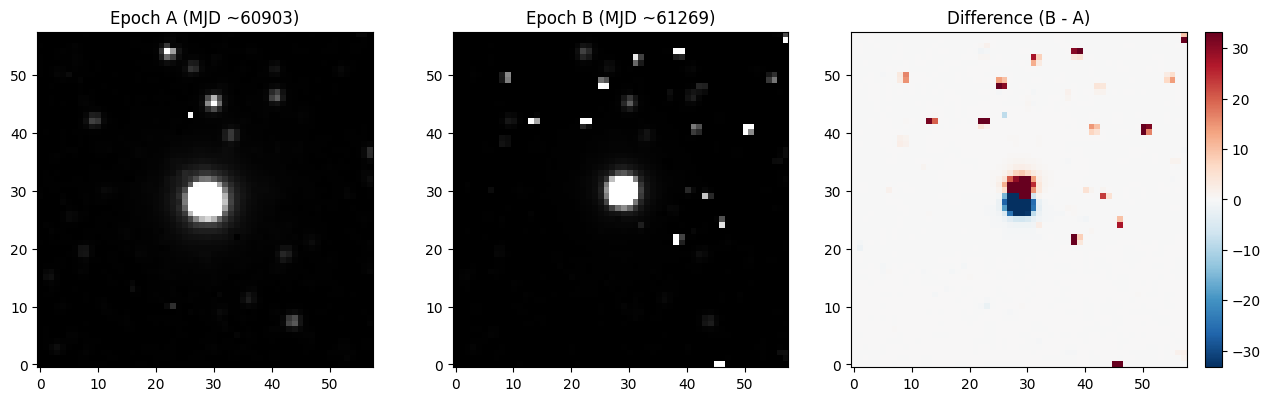

In [54]:
# Run difference on first and last epoch
diff, img_a, img_b = difference(eps[0], eps[-1])

# Symmetric color scale using 99th percentile (ignores extreme edge/cosmic-ray outliers)
vlim = np.nanpercentile(np.abs(diff), 99)

# Find the strongest peak (red) and trough (blue) inside a central 16x16 box
c = diff.shape[0] // 2
box = diff[c-8:c+8, c-8:c+8]
min_yx = np.unravel_index(np.nanargmin(box), box.shape)
max_yx = np.unravel_index(np.nanargmax(box), box.shape)
min_pos = (min_yx[0] + c - 8, min_yx[1] + c - 8)
max_pos = (max_yx[0] + c - 8, max_yx[1] + c - 8)

print(f"Frames used: Epoch A = {len(eps[0])}, Epoch B = {len(eps[-1])}")
print(f"Time baseline: {eps[-1][0]['time'] - eps[0][0]['time']:.1f} days")
print(f"Median of diff: {np.nanmedian(diff):.4f} | vlim (99%): {vlim:.4f}")
print(f"Blue trough (Old pos) at (y, x) = {min_pos}, value = {diff[min_pos]:.2f}")
print(f"Red peak    (New pos) at (y, x) = {max_pos}, value = {diff[max_pos]:.2f}")

# Plot Epoch A, Epoch B, and Difference side by side
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(img_a, origin="lower", cmap="gray", vmin=np.nanpercentile(img_a, 5), vmax=np.nanpercentile(img_a, 99))
axes[0].set_title(f"Epoch A (MJD ~{eps[0][0]['time']:.0f})")

axes[1].imshow(img_b, origin="lower", cmap="gray", vmin=np.nanpercentile(img_b, 5), vmax=np.nanpercentile(img_b, 99))
axes[1].set_title(f"Epoch B (MJD ~{eps[-1][0]['time']:.0f})")

im = axes[2].imshow(diff, origin="lower", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
axes[2].set_title("Difference (B - A)")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

In [55]:
import io, base64, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from astropy.stats import sigma_clip, mad_std

# 1. Fixed coadd: uses median + MAD so cosmic rays/hot pixels get clipped out
def coadd(frames):
    stack = np.array([f["aligned"] for f in frames])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clipped = sigma_clip(stack, sigma=3, cenfunc="median", stdfunc=mad_std, axis=0, masked=True)
    return np.ma.mean(clipped, axis=0).filled(np.nan)

# 2. Difference imaging (Epoch B minus Epoch A) with sky-background subtraction
def difference(frames_a, frames_b, detector=None):
    if detector is not None:
        frames_a = [f for f in frames_a if f["detector"] == detector]
        frames_b = [f for f in frames_b if f["detector"] == detector]
    img_a = coadd(frames_a)
    img_b = coadd(frames_b)
    img_a_sub = img_a - np.nanmedian(img_a)
    img_b_sub = img_b - np.nanmedian(img_b)
    diff = img_b_sub - img_a_sub
    return diff, img_a_sub, img_b_sub

# 3. Convert any 2D numpy array into a base64 PNG string for the React frontend
def array_to_b64png(arr, vmin=None, vmax=None, cmap_name="gray"):
    if vmin is None: vmin = float(np.nanpercentile(arr, 5))
    if vmax is None: vmax = float(np.nanpercentile(arr, 99))
    arr_flipped = np.flipud(arr)  # puts North (+y) at the top of the PNG
    norm = np.clip((arr_flipped - vmin) / (vmax - vmin + 1e-12), 0, 1)
    norm = np.nan_to_num(norm, nan=0.0)
    rgba = (cm.get_cmap(cmap_name)(norm) * 255).astype(np.uint8)
    buf = io.BytesIO()
    plt.imsave(buf, rgba, format="png")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode("ascii")

/tmp/ipykernel_1549/370061746.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  rgba = (cm.get_cmap(cmap_name)(norm) * 255).astype(np.uint8)


Clean coadd + diff succeeded!
Base64 PNG string length: 3370 | Preview: data:image/png;base64,iVBORw0KGgoAAAANSUhEUgA


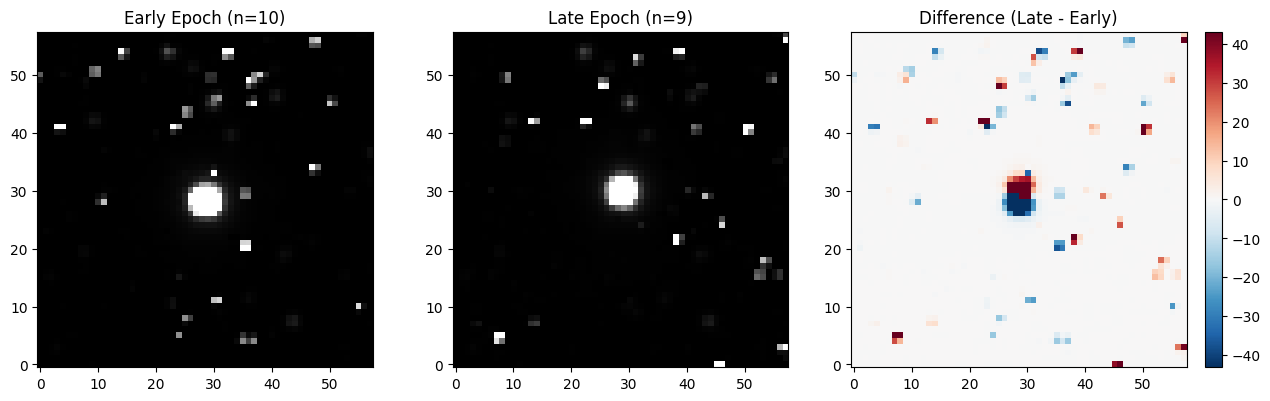

In [56]:
# Use eps[0], eps[-1] if testing Barnard's Star, or epochs[1], epochs[2] in your WISE 0855 notebook
ep_early, ep_late = (eps[0], eps[-1]) if "eps" in globals() else (epochs[1], epochs[2])

diff, img_a, img_b = difference(ep_early, ep_late)
vlim = float(np.nanpercentile(np.abs(diff), 99))

b64_diff = array_to_b64png(diff, vmin=-vlim, vmax=vlim, cmap_name="RdBu_r")
print("Clean coadd + diff succeeded!")
print("Base64 PNG string length:", len(b64_diff), "| Preview:", b64_diff[:45])

# Plot to verify the red cosmic-ray bricks are gone
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(img_a, origin="lower", cmap="gray", vmin=np.nanpercentile(img_a, 5), vmax=np.nanpercentile(img_a, 99))
axes[0].set_title(f"Early Epoch (n={len(ep_early)})")
axes[1].imshow(img_b, origin="lower", cmap="gray", vmin=np.nanpercentile(img_b, 5), vmax=np.nanpercentile(img_b, 99))
axes[1].set_title(f"Late Epoch (n={len(ep_late)})")
im = axes[2].imshow(diff, origin="lower", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
axes[2].set_title("Difference (Late - Early)")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

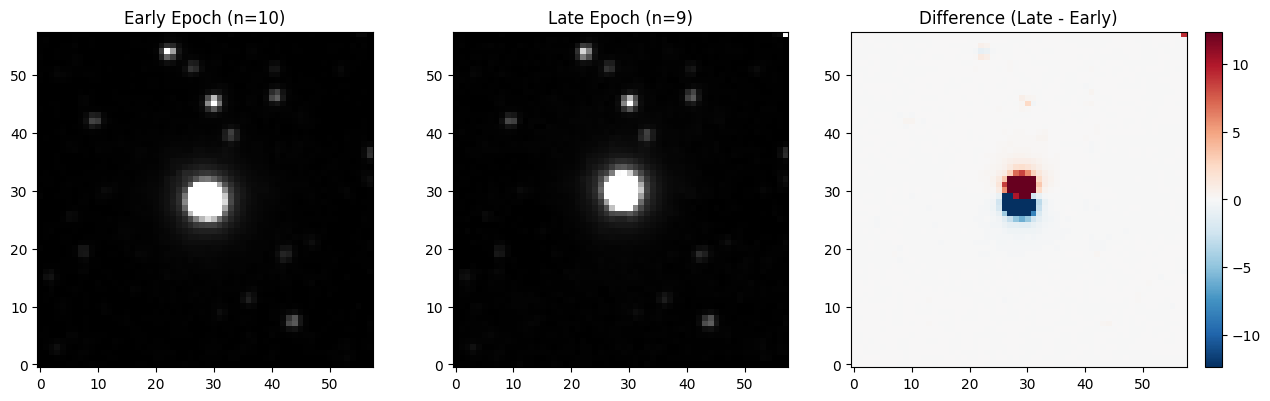

In [57]:
import io, base64, warnings, matplotlib
import numpy as np
import matplotlib.pyplot as plt
from astropy.stats import sigma_clip, mad_std

def coadd(frames):
    stack = np.array([f["aligned"] for f in frames])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clipped = sigma_clip(stack, sigma=2.5, cenfunc="median", stdfunc=mad_std, axis=0, masked=True)
        return np.nanmedian(clipped.filled(np.nan), axis=0)

def difference(frames_a, frames_b, detector=None):
    if detector is not None:
        frames_a = [f for f in frames_a if f["detector"] == detector]
        frames_b = [f for f in frames_b if f["detector"] == detector]
    img_a = coadd(frames_a)
    img_b = coadd(frames_b)
    img_a_sub = img_a - np.nanmedian(img_a)
    img_b_sub = img_b - np.nanmedian(img_b)
    return img_b_sub - img_a_sub, img_a_sub, img_b_sub

def array_to_b64png(arr, vmin=None, vmax=None, cmap_name="gray"):
    if vmin is None: vmin = float(np.nanpercentile(arr, 5))
    if vmax is None: vmax = float(np.nanpercentile(arr, 99))
    arr_flipped = np.flipud(arr)
    norm = np.clip((arr_flipped - vmin) / (vmax - vmin + 1e-12), 0, 1)
    norm = np.nan_to_num(norm, nan=0.0)
    rgba = (matplotlib.colormaps[cmap_name](norm) * 255).astype(np.uint8)
    buf = io.BytesIO()
    plt.imsave(buf, rgba, format="png")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode("ascii")

# Run the test & plot again
ep_early, ep_late = (eps[0], eps[-1]) if "eps" in globals() else (epochs[1], epochs[2])
diff, img_a, img_b = difference(ep_early, ep_late)
vlim = float(np.nanpercentile(np.abs(diff), 99))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(img_a, origin="lower", cmap="gray", vmin=np.nanpercentile(img_a, 5), vmax=np.nanpercentile(img_a, 99))
axes[0].set_title(f"Early Epoch (n={len(ep_early)})")
axes[1].imshow(img_b, origin="lower", cmap="gray", vmin=np.nanpercentile(img_b, 5), vmax=np.nanpercentile(img_b, 99))
axes[1].set_title(f"Late Epoch (n={len(ep_late)})")
im = axes[2].imshow(diff, origin="lower", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
axes[2].set_title("Difference (Late - Early)")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

In [58]:
%%writefile config.py
import os

# Only edit COLLECTIONS when IRSA releases new SPHEREx data (from Cell 6 & 8)
COLLECTIONS = ["spherex_dr1", "spherex_qr3"]

CACHE_DIR = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)

# Detector wavelength ranges in microns (from Cell 41 + IRSA docs)
BANDS = {
    1: (0.75, 1.09),
    2: (1.10, 1.62),
    3: (1.63, 2.41),
    4: (2.42, 3.82),
    5: (3.83, 4.41),
    6: (4.42, 5.00),
}

# Preset challenge targets (from your prompt & Cell 37)
TARGETS = {
    "barnard": {
        "name": "Barnard's Star",
        "ra": 269.452077, "dec": 4.693365, "epoch": 2000.0,
        "pm_ra_arcsec_yr": -0.801, "pm_dec_arcsec_yr": 10.362
    },
    "wise0855": {
        "name": "WISE 0855-0714",
        "ra": 133.795129, "dec": -7.245147, "epoch": 2010.5,
        "pm_ra_arcsec_yr": -8.118, "pm_dec_arcsec_yr": 0.680
    }
}

Writing config.py


In [59]:
%%writefile spherex_core.py
import os, re, time, hashlib, logging, warnings
import numpy as np
import requests
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.time import Time
from astropy.stats import sigma_clip, mad_std
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astroquery.ipac.irsa import Irsa
from reproject import reproject_interp
from concurrent.futures import ThreadPoolExecutor

from config import COLLECTIONS, CACHE_DIR

logging.getLogger("astropy").setLevel(logging.ERROR)

def propagate_coords(ra0, dec0, pm_ra_arcsec_yr=0.0, pm_dec_arcsec_yr=0.0, epoch0=2000.0, to_mjd=61000.0):
    """Move catalog RA/Dec to SPHEREx observing epoch (from Cell 37)."""
    if pm_ra_arcsec_yr == 0.0 and pm_dec_arcsec_yr == 0.0:
        return ra0, dec0
    year_now = Time(to_mjd, format="mjd").decimalyear
    dt = year_now - epoch0
    ra1 = ra0 + (pm_ra_arcsec_yr * dt / 3600.0) / np.cos(np.radians(dec0))
    dec1 = dec0 + (pm_dec_arcsec_yr * dt / 3600.0)
    return float(ra1), float(dec1)

def find_images(coord, fov_deg):
    """Query IRSA SIA across active SPHEREx collections and parse detector from URL (Cell 8 & 42)."""
    found = []
    for col in COLLECTIONS:
        try:
            r = Irsa.query_sia(pos=(coord, (fov_deg / 2) * u.deg), collection=col)
            t = r.to_table() if hasattr(r, "to_table") else r
        except Exception as e:
            print(col, "query failed:", str(e)[:60])
            continue
        for row in t:
            url = str(row["access_url"])
            m = re.search(r"_\d+D(\d)_spx", url)
            found.append({
                "url": url,
                "mjd": float(row["t_min"]),
                "detector": int(m.group(1)) if m else None,
                "collection": col
            })
    found.sort(key=lambda d: d["mjd"])
    return found

def load_frame(meta, coord, fov_deg):
    """Download & cache FITS cutout with 503 retries and extract image, flags, and wavelength (Cell 33)."""
    key = hashlib.md5(f"{meta['url']}{coord.ra.deg:.5f}{coord.dec.deg:.5f}{fov_deg}".encode()).hexdigest()
    path = f"{CACHE_DIR}/{key}.fits"
    if not os.path.exists(path):
        url = f"{meta['url']}?center={coord.ra.deg},{coord.dec.deg}&size={fov_deg}"
        ok = False
        for attempt in range(4):
            try:
                r = requests.get(url, timeout=120)
                if r.status_code == 503:
                    time.sleep(2 ** attempt)
                    continue
                r.raise_for_status()
                with open(path, "wb") as f_out:
                    f_out.write(r.content)
                ok = True
                break
            except Exception:
                time.sleep(2 ** attempt)
        if not ok:
            return None

    try:
        with fits.open(path) as hdul:
            hdr = hdul["IMAGE"].header.copy()
            x, y = WCS(hdr).world_to_pixel(coord)
            swcs = WCS(hdr, fobj=hdul, key="W")
            swcs.sip = None
            wave, _ = swcs.pixel_to_world(x, y)
            return {
                "time": float(hdr["MJD-AVG"]),
                "detector": int(hdr["DETECTOR"]),
                "wave_um": float(wave.to(u.um).value),
                "image": hdul["IMAGE"].data.astype("float32"),
                "flags": hdul["FLAGS"].data.copy(),
                "header": hdr,
                "collection": meta["collection"]
            }
    except Exception as e:
        print("read failed:", str(e)[:60])
        return None

def make_grid(coord, fov_deg, pix_arcsec):
    """Create shared north-up TAN WCS grid (Cell 38)."""
    n = int(round(fov_deg * 3600 / pix_arcsec))
    w = WCS(naxis=2)
    w.wcs.ctype = ["RA---TAN", "DEC--TAN"]
    w.wcs.crval = [coord.ra.deg, coord.dec.deg]
    w.wcs.crpix = [(n + 1) / 2, (n + 1) / 2]
    w.wcs.cdelt = [-pix_arcsec / 3600, pix_arcsec / 3600]
    return w, n

def build_cube(ra, dec, fov_deg=0.1, detectors=(5, 6), max_frames=40):
    """Download, cache, and reproject SPHEREx cutouts onto a common grid (no shape filtering!)."""
    coord = SkyCoord(ra * u.deg, dec * u.deg)
    imgs = [m for m in find_images(coord, fov_deg) if m["detector"] in detectors]
    if not imgs:
        return {"frames": [], "message": "no SPHEREx images cover this position"}
    if len(imgs) > max_frames:
        imgs = [imgs[i] for i in np.linspace(0, len(imgs) - 1, max_frames).astype(int)]
    with ThreadPoolExecutor(max_workers=3) as ex:
        loaded = [f for f in ex.map(lambda m: load_frame(m, coord, fov_deg), imgs) if f]
    if not loaded:
        return {"frames": [], "message": "downloads failed"}

    scales = proj_plane_pixel_scales(WCS(loaded[0]["header"])) * 3600
    pix_arcsec = float(np.mean(scales))
    grid, n = make_grid(coord, fov_deg, pix_arcsec)
    for f in loaded:
        f["aligned"], _ = reproject_interp((f["image"], WCS(f["header"])), grid, shape_out=(n, n))
    loaded.sort(key=lambda f: f["time"])
    return {"frames": loaded, "grid": grid, "n": n, "pix_arcsec": pix_arcsec, "center": (ra, dec)}

def group_epochs(frames, gap_days=30):
    """Split time-sorted frames into visits separated by >gap_days (Cell 38)."""
    epochs, cur = [], [frames[0]]
    for a, b in zip(frames[:-1], frames[1:]):
        if b["time"] - a["time"] > gap_days:
            epochs.append(cur)
            cur = []
        cur.append(b)
    epochs.append(cur)
    return epochs

def coadd(frames):
    """Median + MAD sigma-clipped stack to reject cosmic rays and hot pixels."""
    stack = np.array([f["aligned"] for f in frames])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clipped = sigma_clip(stack, sigma=2.5, cenfunc="median", stdfunc=mad_std, axis=0, masked=True)
        return np.nanmedian(clipped.filled(np.nan), axis=0)

def difference(frames_a, frames_b, detector=None):
    """Subtract background-corrected Early Epoch from Late Epoch."""
    if detector is not None:
        frames_a = [f for f in frames_a if f["detector"] == detector]
        frames_b = [f for f in frames_b if f["detector"] == detector]
    img_a = coadd(frames_a)
    img_b = coadd(frames_b)
    img_a_sub = img_a - np.nanmedian(img_a)
    img_b_sub = img_b - np.nanmedian(img_b)
    return img_b_sub - img_a_sub, img_a_sub, img_b_sub

Writing spherex_core.py


In [60]:
%%writefile serializers.py
import io, base64, matplotlib
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
from spherex_core import group_epochs, coadd, difference

def array_to_b64png(arr, vmin=None, vmax=None, cmap_name="gray"):
    if vmin is None: vmin = float(np.nanpercentile(arr, 5))
    if vmax is None: vmax = float(np.nanpercentile(arr, 99))
    arr_flipped = np.flipud(arr)
    norm = np.clip((arr_flipped - vmin) / (vmax - vmin + 1e-12), 0, 1)
    norm = np.nan_to_num(norm, nan=0.0)
    rgba = (matplotlib.colormaps[cmap_name](norm) * 255).astype(np.uint8)
    buf = io.BytesIO()
    plt.imsave(buf, rgba, format="png")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode("ascii")

def package_cube_json(cube):
    frames = cube.get("frames", [])
    if not frames:
        return {"error": cube.get("message", "No frames found")}

    eps = group_epochs(frames)

    frames_out = []
    for idx, f in enumerate(frames):
        mjd = float(f["time"])
        frames_out.append({
            "index": idx,
            "mjd": round(mjd, 4),
            "iso_date": Time(mjd, format="mjd").isot[:10],
            "detector": int(f["detector"]),
            "wave_um": round(float(f.get("wave_um", 0.0)), 3),
            "collection": f["collection"],
            "png_b64": array_to_b64png(f["aligned"], cmap_name="gray")
        })

    epochs_out = []
    for idx, ep in enumerate(eps):
        mean_mjd = float(np.mean([f["time"] for f in ep]))
        ep_img = coadd(ep)
        epochs_out.append({
            "epoch_id": idx,
            "mjd_mean": round(mean_mjd, 2),
            "iso_date": Time(mean_mjd, format="mjd").isot[:10],
            "n_frames": len(ep),
            "png_b64": array_to_b64png(ep_img, cmap_name="gray")
        })

    good_eps = [ep for ep in eps if len(ep) >= 2] or eps
    ep_a, ep_b = good_eps[0], good_eps[-1]
    diff, _, _ = difference(ep_a, ep_b)
    vlim = float(np.nanpercentile(np.abs(diff), 99))

    return {
        "center": {"ra": cube["center"][0], "dec": cube["center"][1]},
        "grid_size_px": cube["n"],
        "pix_scale_arcsec": round(cube["pix_arcsec"], 3),
        "n_frames_total": len(frames_out),
        "n_epochs": len(epochs_out),
        "frames": frames_out,
        "epochs": epochs_out,
        "difference": {
            "mjd_early": round(float(np.mean([f["time"] for f in ep_a])), 2),
            "mjd_late": round(float(np.mean([f["time"] for f in ep_b])), 2),
            "baseline_days": round(float(np.mean([f["time"] for f in ep_b]) - np.mean([f["time"] for f in ep_a])), 1),
            "vlim_mjy_sr": round(vlim, 3),
            "png_b64": array_to_b64png(diff, vmin=-vlim, vmax=vlim, cmap_name="RdBu_r")
        }
    }

Writing serializers.py


In [61]:
from config import TARGETS
from spherex_core import propagate_coords, build_cube
from serializers import package_cube_json

t = TARGETS["barnard"]
ra_now, dec_now = propagate_coords(t["ra"], t["dec"], t["pm_ra_arcsec_yr"], t["pm_dec_arcsec_yr"], t["epoch"])
cube = build_cube(ra_now, dec_now, fov_deg=0.1, detectors=(5, 6), max_frames=30)
payload = package_cube_json(cube)

print("Propagated Barnard RA/Dec:", round(ra_now, 5), round(dec_now, 5))
print("Frames:", payload["n_frames_total"], "| Epochs:", payload["n_epochs"])
print("Difference summary:", {k: v for k, v in payload["difference"].items() if k != "png_b64"})

Propagated Barnard RA/Dec: 269.4463 4.76788
Frames: 30 | Epochs: 4
Difference summary: {'mjd_early': 60910.54, 'mjd_late': 61274.88, 'baseline_days': 364.3, 'vlim_mjy_sr': 11.611}


In [62]:
%%writefile -a spherex_core.py

def compute_spectrum(ra, dec, fov_deg=0.1, max_per_det=8, r_ap=2.5):
    """Measure empirical-noise aperture flux & SNR across D1-D6 at (ra, dec) (from Cell 44)."""
    coord = SkyCoord(ra * u.deg, dec * u.deg)
    all_imgs = find_images(coord, fov_deg)
    if not all_imgs:
        return []

    # Pick up to max_per_det frames per detector (D1..D6)
    picked = []
    for d in range(1, 7):
        d_imgs = [m for m in all_imgs if m["detector"] == d]
        if len(d_imgs) > max_per_det:
            d_imgs = [d_imgs[i] for i in np.linspace(0, len(d_imgs) - 1, max_per_det).astype(int)]
        picked.extend(d_imgs)

    with ThreadPoolExecutor(max_workers=3) as ex:
        loaded = [f for f in ex.map(lambda m: load_frame(m, coord, fov_deg), picked) if f]
    if not loaded:
        return []

    scales = proj_plane_pixel_scales(WCS(loaded[0]["header"])) * 3600
    grid, n = make_grid(coord, fov_deg, float(np.mean(scales)))
    c = (n - 1) / 2.0
    yy, xx = np.mgrid[0:n, 0:n]

    def aper_mean(img, cx, cy):
        m = np.hypot(xx - cx, yy - cy) <= r_ap
        v = img[m]
        return float(np.nanmean(v)) if np.isfinite(v).sum() > 0.8 * m.sum() else np.nan

    spectrum = []
    for d in range(1, 7):
        g = [f for f in loaded if f["detector"] == d]
        if len(g) < 2:
            continue
        for f in g:
            f["aligned"], _ = reproject_interp((f["image"], WCS(f["header"])), grid, shape_out=(n, n))
        img = coadd(g)

        # Empirical noise: measure same aperture at grid positions >8 px away from center
        vals = [
            aper_mean(img, x, y)
            for x in range(8, n - 8, 3)
            for y in range(8, n - 8, 3)
            if np.hypot(x - c, y - c) > 8
        ]
        vals = np.array([v for v in vals if np.isfinite(v)])
        if len(vals) == 0:
            continue
        med = float(np.median(vals))
        sig = float(1.4826 * np.median(np.abs(vals - med)))
        excess = aper_mean(img, c, c) - med
        wave = float(np.mean([f["wave_um"] for f in g]))
        spectrum.append({
            "detector": d,
            "n_frames": len(g),
            "wave_um": round(wave, 3),
            "flux_mjy_sr": round(excess, 4),
            "err_mjy_sr": round(sig, 4),
            "snr": round(excess / (sig + 1e-12), 1)
        })
    return spectrum

Appending to spherex_core.py


In [63]:
%%writefile main.py
from fastapi import FastAPI, Query
from fastapi.middleware.cors import CORSMiddleware
from config import TARGETS, BANDS
from spherex_core import propagate_coords, build_cube, compute_spectrum
from serializers import package_cube_json

app = FastAPI(title="Project Astraea SPHEREx API")

# Enable CORS so React+Vite (localhost:5173) can call this backend
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_methods=["*"],
    allow_headers=["*"],
)

@app.get("/api/targets")
def get_targets():
    out = {}
    for key, t in TARGETS.items():
        ra_now, dec_now = propagate_coords(
            t["ra"], t["dec"], t["pm_ra_arcsec_yr"], t["pm_dec_arcsec_yr"], t["epoch"]
        )
        out[key] = {**t, "ra_2026": round(ra_now, 6), "dec_2026": round(dec_now, 6)}
    return {"targets": out, "bands_um": BANDS}

@app.get("/api/frames")
def get_frames(
    ra: float = Query(..., description="Right Ascension in degrees"),
    dec: float = Query(..., description="Declination in degrees"),
    fov: float = Query(0.1, ge=0.03, le=0.3, description="Field of view in degrees"),
    detectors: str = Query("5,6", description="Comma-separated detector numbers, e.g. 5,6"),
    max_frames: int = Query(30, ge=4, le=80)
):
    det_tuple = tuple(int(x.strip()) for x in detectors.split(",") if x.strip().isdigit())
    cube = build_cube(ra, dec, fov_deg=fov, detectors=det_tuple, max_frames=max_frames)
    return package_cube_json(cube)

@app.get("/api/spectrum")
def get_spectrum(
    ra: float = Query(..., description="Right Ascension in degrees"),
    dec: float = Query(..., description="Declination in degrees"),
    fov: float = Query(0.1, ge=0.03, le=0.3)
):
    spec = compute_spectrum(ra, dec, fov_deg=fov)
    return {"center": {"ra": ra, "dec": dec}, "spectrum": spec}

Writing main.py


In [65]:
!pip install -q fastapi httpx uvicorn

import importlib, spherex_core
importlib.reload(spherex_core)  # reload so compute_spectrum is picked up
from fastapi.testclient import TestClient
from main import app

client = TestClient(app)

# 1. Test /api/targets
r1 = client.get("/api/targets").json()
print("1. /api/targets ->", r1["targets"]["barnard"])

# 2. Test /api/frames with URL query parameters
ra_b = r1["targets"]["barnard"]["ra_2026"]
dec_b = r1["targets"]["barnard"]["dec_2026"]
r2 = client.get(f"/api/frames?ra={ra_b}&dec={dec_b}&fov=0.1&detectors=5,6&max_frames=30").json()
print("2. /api/frames  -> status OK, frames:", r2["n_frames_total"], "epochs:", r2["n_epochs"])

# 3. Test /api/spectrum on Barnard's Star
r3 = client.get(f"/api/spectrum?ra={ra_b}&dec={dec_b}&fov=0.1").json()
print("3. /api/spectrum ->")
for band in r3["spectrum"]:
    print("  ", band)

1. /api/targets -> {'name': "Barnard's Star", 'ra': 269.452077, 'dec': 4.693365, 'epoch': 2000.0, 'pm_ra_arcsec_yr': -0.801, 'pm_dec_arcsec_yr': 10.362, 'ra_2026': 269.446298, 'dec_2026': 4.767878}
2. /api/frames  -> status OK, frames: 30 epochs: 4


ValueError: Out of range float values are not JSON compliant: nan

In [66]:
%%writefile spherex_core.py
import os, re, time, hashlib, logging, warnings
import numpy as np
import requests
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.time import Time
from astropy.stats import sigma_clip, mad_std
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astroquery.ipac.irsa import Irsa
from reproject import reproject_interp
from concurrent.futures import ThreadPoolExecutor

from config import COLLECTIONS, CACHE_DIR, BANDS

logging.getLogger("astropy").setLevel(logging.ERROR)

def propagate_coords(ra0, dec0, pm_ra_arcsec_yr=0.0, pm_dec_arcsec_yr=0.0, epoch0=2000.0, to_mjd=61000.0):
    if pm_ra_arcsec_yr == 0.0 and pm_dec_arcsec_yr == 0.0:
        return ra0, dec0
    year_now = Time(to_mjd, format="mjd").decimalyear
    dt = year_now - epoch0
    ra1 = ra0 + (pm_ra_arcsec_yr * dt / 3600.0) / np.cos(np.radians(dec0))
    dec1 = dec0 + (pm_dec_arcsec_yr * dt / 3600.0)
    return float(ra1), float(dec1)

def find_images(coord, fov_deg):
    found = []
    for col in COLLECTIONS:
        try:
            r = Irsa.query_sia(pos=(coord, (fov_deg / 2) * u.deg), collection=col)
            t = r.to_table() if hasattr(r, "to_table") else r
        except Exception as e:
            print(col, "query failed:", str(e)[:60])
            continue
        for row in t:
            url = str(row["access_url"])
            m = re.search(r"_\d+D(\d)_spx", url)
            found.append({
                "url": url,
                "mjd": float(row["t_min"]),
                "detector": int(m.group(1)) if m else None,
                "collection": col
            })
    found.sort(key=lambda d: d["mjd"])
    return found

def load_frame(meta, coord, fov_deg):
    key = hashlib.md5(f"{meta['url']}{coord.ra.deg:.5f}{coord.dec.deg:.5f}{fov_deg}".encode()).hexdigest()
    path = f"{CACHE_DIR}/{key}.fits"
    if not os.path.exists(path):
        url = f"{meta['url']}?center={coord.ra.deg},{coord.dec.deg}&size={fov_deg}"
        ok = False
        for attempt in range(4):
            try:
                r = requests.get(url, timeout=120)
                if r.status_code == 503:
                    time.sleep(2 ** attempt)
                    continue
                r.raise_for_status()
                with open(path, "wb") as f_out:
                    f_out.write(r.content)
                ok = True
                break
            except Exception:
                time.sleep(2 ** attempt)
        if not ok:
            return None

    try:
        with fits.open(path) as hdul:
            hdr = hdul["IMAGE"].header.copy()
            det = int(hdr["DETECTOR"])
            x, y = WCS(hdr).world_to_pixel(coord)
            try:
                swcs = WCS(hdr, fobj=hdul, key="W")
                swcs.sip = None
                wave_val = float(swcs.pixel_to_world(x, y)[0].to(u.um).value)
            except Exception:
                wave_val = np.nan
            if not np.isfinite(wave_val) and det in BANDS:
                wave_val = float(np.mean(BANDS[det]))
            return {
                "time": float(hdr["MJD-AVG"]),
                "detector": det,
                "wave_um": wave_val,
                "image": hdul["IMAGE"].data.astype("float32"),
                "flags": hdul["FLAGS"].data.copy(),
                "header": hdr,
                "collection": meta["collection"]
            }
    except Exception as e:
        print("read failed:", str(e)[:60])
        return None

def make_grid(coord, fov_deg, pix_arcsec):
    n = int(round(fov_deg * 3600 / pix_arcsec))
    w = WCS(naxis=2)
    w.wcs.ctype = ["RA---TAN", "DEC--TAN"]
    w.wcs.crval = [coord.ra.deg, coord.dec.deg]
    w.wcs.crpix = [(n + 1) / 2, (n + 1) / 2]
    w.wcs.cdelt = [-pix_arcsec / 3600, pix_arcsec / 3600]
    return w, n

def build_cube(ra, dec, fov_deg=0.1, detectors=(5, 6), max_frames=40):
    coord = SkyCoord(ra * u.deg, dec * u.deg)
    imgs = [m for m in find_images(coord, fov_deg) if m["detector"] in detectors]
    if not imgs:
        return {"frames": [], "message": "no SPHEREx images cover this position"}
    if len(imgs) > max_frames:
        imgs = [imgs[i] for i in np.linspace(0, len(imgs) - 1, max_frames).astype(int)]
    with ThreadPoolExecutor(max_workers=3) as ex:
        loaded = [f for f in ex.map(lambda m: load_frame(m, coord, fov_deg), imgs) if f]
    if not loaded:
        return {"frames": [], "message": "downloads failed"}

    scales = proj_plane_pixel_scales(WCS(loaded[0]["header"])) * 3600
    pix_arcsec = float(np.mean(scales))
    grid, n = make_grid(coord, fov_deg, pix_arcsec)
    for f in loaded:
        f["aligned"], _ = reproject_interp((f["image"], WCS(f["header"])), grid, shape_out=(n, n))
    loaded.sort(key=lambda f: f["time"])
    return {"frames": loaded, "grid": grid, "n": n, "pix_arcsec": pix_arcsec, "center": (ra, dec)}

def group_epochs(frames, gap_days=30):
    epochs, cur = [], [frames[0]]
    for a, b in zip(frames[:-1], frames[1:]):
        if b["time"] - a["time"] > gap_days:
            epochs.append(cur)
            cur = []
        cur.append(b)
    epochs.append(cur)
    return epochs

def coadd(frames):
    stack = np.array([f["aligned"] for f in frames])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clipped = sigma_clip(stack, sigma=2.5, cenfunc="median", stdfunc=mad_std, axis=0, masked=True)
        return np.nanmedian(clipped.filled(np.nan), axis=0)

def difference(frames_a, frames_b, detector=None):
    if detector is not None:
        frames_a = [f for f in frames_a if f["detector"] == detector]
        frames_b = [f for f in frames_b if f["detector"] == detector]
    img_a = coadd(frames_a)
    img_b = coadd(frames_b)
    img_a_sub = img_a - np.nanmedian(img_a)
    img_b_sub = img_b - np.nanmedian(img_b)
    return img_b_sub - img_a_sub, img_a_sub, img_b_sub

def compute_spectrum(ra, dec, fov_deg=0.1, max_per_det=8, r_ap=2.5):
    coord = SkyCoord(ra * u.deg, dec * u.deg)
    all_imgs = find_images(coord, fov_deg)
    if not all_imgs:
        return []

    picked = []
    for d in range(1, 7):
        d_imgs = [m for m in all_imgs if m["detector"] == d]
        if len(d_imgs) > max_per_det:
            d_imgs = [d_imgs[i] for i in np.linspace(0, len(d_imgs) - 1, max_per_det).astype(int)]
        picked.extend(d_imgs)

    with ThreadPoolExecutor(max_workers=3) as ex:
        loaded = [f for f in ex.map(lambda m: load_frame(m, coord, fov_deg), picked) if f]
    if not loaded:
        return []

    scales = proj_plane_pixel_scales(WCS(loaded[0]["header"])) * 3600
    grid, n = make_grid(coord, fov_deg, float(np.mean(scales)))
    c = (n - 1) / 2.0
    yy, xx = np.mgrid[0:n, 0:n]

    def aper_mean(img, cx, cy):
        m = np.hypot(xx - cx, yy - cy) <= r_ap
        v = img[m]
        return float(np.nanmean(v)) if np.isfinite(v).sum() > 0.5 * m.sum() else np.nan

    spectrum = []
    for d in range(1, 7):
        g = [f for f in loaded if f["detector"] == d]
        if len(g) < 2:
            continue
        for f in g:
            f["aligned"], _ = reproject_interp((f["image"], WCS(f["header"])), grid, shape_out=(n, n))
        img = coadd(g)

        vals = [
            aper_mean(img, x, y)
            for x in range(8, n - 8, 3)
            for y in range(8, n - 8, 3)
            if np.hypot(x - c, y - c) > 8
        ]
        vals = np.array([v for v in vals if np.isfinite(v)])
        center_flux = aper_mean(img, c, c)
        if len(vals) == 0 or not np.isfinite(center_flux):
            continue

        med = float(np.median(vals))
        sig = float(1.4826 * np.median(np.abs(vals - med)))
        if not np.isfinite(sig) or sig <= 0:
            continue

        excess = float(center_flux - med)
        wave = float(np.nanmean([f["wave_um"] for f in g]))
        if not np.isfinite(wave):
            wave = float(np.mean(BANDS[d]))

        spectrum.append({
            "detector": d,
            "n_frames": len(g),
            "wave_um": round(wave, 3),
            "flux_mjy_sr": round(excess, 4),
            "err_mjy_sr": round(sig, 4),
            "snr": round(excess / sig, 1)
        })
    return spectrum

Overwriting spherex_core.py


In [67]:
import importlib, spherex_core, main
importlib.reload(spherex_core)
importlib.reload(main)
from fastapi.testclient import TestClient

client = TestClient(main.app)
r3 = client.get(f"/api/spectrum?ra={ra_b}&dec={dec_b}&fov=0.1").json()
print("3. /api/spectrum ->")
for band in r3["spectrum"]:
    print("  ", band)

3. /api/spectrum ->
   {'detector': 1, 'n_frames': 7, 'wave_um': 0.91, 'flux_mjy_sr': 258.2744, 'err_mjy_sr': 0.1863, 'snr': 1386.0}
   {'detector': 2, 'n_frames': 8, 'wave_um': 1.334, 'flux_mjy_sr': 206.3495, 'err_mjy_sr': 0.2062, 'snr': 1000.8}
   {'detector': 3, 'n_frames': 8, 'wave_um': 1.96, 'flux_mjy_sr': 282.1299, 'err_mjy_sr': 0.2202, 'snr': 1281.2}
   {'detector': 4, 'n_frames': 8, 'wave_um': 3.049, 'flux_mjy_sr': 300.9873, 'err_mjy_sr': 0.1154, 'snr': 2607.2}
   {'detector': 5, 'n_frames': 8, 'wave_um': 4.123, 'flux_mjy_sr': 297.1566, 'err_mjy_sr': 0.066, 'snr': 4502.7}
   {'detector': 6, 'n_frames': 8, 'wave_um': 4.638, 'flux_mjy_sr': 222.6783, 'err_mjy_sr': 0.0539, 'snr': 4134.3}


In [68]:
from astropy.coordinates import SkyCoord

benchmark_names = [
    "Barnard's Star",
    "eps Ind B",
    "WISE J085510.83-071442.5",
    "RW Aur",
    "R Dra"
]

for name in benchmark_names:
    c = SkyCoord.from_name(name)
    print(f"{name:28s} -> RA: {c.ra.deg:10.6f}, Dec: {c.dec.deg:10.6f}")

Barnard's Star               -> RA: 269.452077, Dec:   4.693365
eps Ind B                    -> RA: 331.044147, Dec: -56.782844
WISE J085510.83-071442.5     -> RA: 133.818908, Dec:  -7.247048
RW Aur                       -> RA:  76.956526, Dec:  30.401438
R Dra                        -> RA: 248.167611, Dec:  66.754979


In [69]:
from astroquery.simbad import Simbad

s = Simbad()
s.add_votable_fields("pmra", "pmdec")
for name in ["Barnard's Star", "eps Ind B", "WISE J085510.83-071442.5", "RW Aur", "R Dra"]:
    t = s.query_object(name)
    # Note: modern astroquery uses 'pmra' and 'pmdec' in mas/yr (divide by 1000 for arcsec/yr)
    cols = [c for c in t.colnames if "pm" in c.lower()]
    print(f"{name:28s} ->", {c: float(t[c][0]) for c in cols})

DALServiceError: Unable to access the capabilities endpoint at:
- https://simbad.cds.unistra.fr/simbad/sim-tap/capabilities: 404 Not Found
- https://simbad.cds.unistra.fr/simbad/capabilities: 404 Not Found

This could mean:
1. The service URL is incorrect
2. The service is temporarily unavailable
3. The service doesn't support this protocol
4. If a 503 was encountered, retry after the suggested delay.


In [70]:
%%writefile config.py
import os

COLLECTIONS = ["spherex_dr1", "spherex_qr3"]
CACHE_DIR = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)

BANDS = {
    1: (0.75, 1.09),
    2: (1.10, 1.62),
    3: (1.63, 2.41),
    4: (2.42, 3.82),
    5: (3.83, 4.41),
    6: (4.42, 5.00),
}

# Verified NASA Space Apps 2026 Benchmark Targets
TARGETS = {
    "barnard": {
        "name": "Barnard's Star",
        "category": "High Proper Motion Star",
        "ra": 269.452077, "dec": 4.693365, "epoch": 2000.0,
        "pm_ra_arcsec_yr": -0.8015, "pm_dec_arcsec_yr": 10.3624
    },
    "eps_ind_b": {
        "name": "Epsilon Indi B",
        "category": "Binary Brown Dwarf System",
        "ra": 331.044147, "dec": -56.782844, "epoch": 2000.0,
        "pm_ra_arcsec_yr": 3.9614, "pm_dec_arcsec_yr": -2.5383
    },
    "wise0855": {
        "name": "WISE 0855-0714",
        "category": "Fast-Moving Y-type Brown Dwarf (~250 K)",
        "ra": 133.795129, "dec": -7.245147, "epoch": 2010.5,
        "pm_ra_arcsec_yr": -8.118, "pm_dec_arcsec_yr": 0.680
    },
    "rw_aur": {
        "name": "RW Aurigae",
        "category": "T Tauri Variable Star",
        "ra": 76.956526, "dec": 30.401438, "epoch": 2000.0,
        "pm_ra_arcsec_yr": 0.003, "pm_dec_arcsec_yr": -0.024
    },
    "r_dra": {
        "name": "R Draconis",
        "category": "Mira Cet Variable Star",
        "ra": 248.167611, "dec": 66.754979, "epoch": 2000.0,
        "pm_ra_arcsec_yr": -0.006, "pm_dec_arcsec_yr": -0.033
    }
}

Overwriting config.py


In [71]:
%%writefile analytics.py
import numpy as np
from scipy.ndimage import gaussian_filter, maximum_filter

def compute_sky_health(cube):
    """Transparent, formula-defined Sky Health Index (Blueprint Group II #3)."""
    frames = cube.get("frames", [])
    if not frames:
        return None

    aligned_stack = np.array([f["aligned"] for f in frames])
    valid_coverage = float(np.isfinite(aligned_stack).mean() * 100.0)

    raw_flags = np.concatenate([f["flags"].ravel() for f in frames])
    zero_flag_pct = float((raw_flags == 0).mean() * 100.0)

    mjd_span = float(frames[-1]["time"] - frames[0]["time"]) if len(frames) > 1 else 0.0
    time_baseline_score = min(100.0, (mjd_span / 180.0) * 100.0)

    health_score = 0.55 * valid_coverage + 0.25 * time_baseline_score + 0.20 * min(100.0, zero_flag_pct + 50.0)
    status = "Excellent" if health_score >= 85 else ("Good" if health_score >= 70 else "Moderate")

    return {
        "score_pct": round(health_score, 1),
        "status": status,
        "valid_coverage_pct": round(valid_coverage, 1),
        "unflagged_raw_pct": round(zero_flag_pct, 1),
        "time_baseline_days": round(mjd_span, 1),
        "n_frames": len(frames),
        "formula": "0.55*valid_coverage_pct + 0.25*min(100, baseline_days/180*100) + 0.20*flag_quality"
    }

def detect_anomalies(diff_img, img_early, img_late, grid_wcs, z_thresh=4.5, border=5):
    """
    Unsupervised Difference Blob Detector + Uncertainty-Aware Ranking (Blueprint Group I #3/#4 & II #2).
    """
    n = diff_img.shape[0]
    clean_diff = np.nan_to_num(diff_img, nan=0.0)
    sm_diff = gaussian_filter(clean_diff, sigma=0.8)

    finite_vals = sm_diff[border:n-border, border:n-border]
    med = float(np.median(finite_vals))
    sigma_noise = float(1.4826 * np.median(np.abs(finite_vals - med))) + 1e-12
    z_map = (sm_diff - med) / sigma_noise

    pos_max = (z_map == maximum_filter(z_map, size=5)) & (z_map >= z_thresh)
    neg_min = (-z_map == maximum_filter(-z_map, size=5)) & (-z_map >= z_thresh)

    mask = np.zeros_like(z_map, dtype=bool)
    mask[border:n-border, border:n-border] = True
    pos_yx = np.argwhere(pos_max & mask)
    neg_yx = np.argwhere(neg_min & mask)

    used_neg = set()
    candidates = []

    for py, px in pos_yx:
        z_pos = float(z_map[py, px])
        best_neg_idx, best_dist = None, 999.0
        for idx, (ny, nx) in enumerate(neg_yx):
            if idx in used_neg:
                continue
            dist = float(np.hypot(py - ny, px - nx))
            if 0.8 <= dist <= 5.5 and dist < best_dist:
                best_dist = dist
                best_neg_idx = idx

        if best_neg_idx is not None:
            used_neg.add(best_neg_idx)
            ny, nx = neg_yx[best_neg_idx]
            z_neg = float(abs(z_map[ny, nx]))
            snr_combined = round(float(np.hypot(z_pos, z_neg)), 1)
            cy, cx = (py + ny) / 2.0, (px + nx) / 2.0
            cand_type = "Moving Object Candidate"
            shift_px = round(best_dist, 2)
        else:
            snr_combined = round(z_pos, 1)
            cy, cx = float(py), float(px)
            cand_type = "Variable Source Candidate (Brightening)"
            shift_px = 0.0

        sky = grid_wcs.pixel_to_world(cx, cy)
        conf = round(float(min(0.95, max(0.15, (snr_combined - z_thresh) / 25.0 + 0.45))), 2)
        status = "High Priority Review" if snr_combined >= 8.0 else "Candidate - Review"

        candidates.append({
            "type": cand_type,
            "x_px": round(float(cx), 2),
            "y_px": round(float(cy), 2),
            "ra": round(float(sky.ra.deg), 6),
            "dec": round(float(sky.dec.deg), 6),
            "snr_zscore": snr_combined,
            "shift_px": shift_px,
            "confidence": conf,
            "status": status
        })

    for idx, (ny, nx) in enumerate(neg_yx):
        if idx in used_neg:
            continue
        z_neg = round(float(abs(z_map[ny, nx])), 1)
        sky = grid_wcs.pixel_to_world(float(nx), float(ny))
        conf = round(float(min(0.90, max(0.15, (z_neg - z_thresh) / 25.0 + 0.40))), 2)
        candidates.append({
            "type": "Variable Source Candidate (Dimming)",
            "x_px": float(nx),
            "y_px": float(ny),
            "ra": round(float(sky.ra.deg), 6),
            "dec": round(float(sky.dec.deg), 6),
            "snr_zscore": z_neg,
            "shift_px": 0.0,
            "confidence": conf,
            "status": "Candidate - Review"
        })

    candidates.sort(key=lambda d: d["snr_zscore"], reverse=True)
    return candidates[:8]

Writing analytics.py


In [72]:
from analytics import compute_sky_health, detect_anomalies
from spherex_core import group_epochs, difference

eps = group_epochs(cube["frames"])
diff_img, img_a, img_b = difference(eps[0], eps[-1])

print("Sky Health Index:", compute_sky_health(cube))
print("Detected Candidates:")
for c in detect_anomalies(diff_img, img_a, img_b, cube["grid"]):
    print(" ", c)

Sky Health Index: {'score_pct': 83.2, 'status': 'Good', 'valid_coverage_pct': 87.4, 'unflagged_raw_pct': 0.7, 'time_baseline_days': 402.8, 'n_frames': 30, 'formula': '0.55*valid_coverage_pct + 0.25*min(100, baseline_days/180*100) + 0.20*flag_quality'}
Detected Candidates:
  {'type': 'Moving Object Candidate', 'x_px': 28.5, 'y_px': 29.0, 'ra': 269.446298, 'dec': 4.768734, 'snr_zscore': 24106.4, 'shift_px': 2.24, 'confidence': 0.95, 'status': 'High Priority Review'}
  {'type': 'Variable Source Candidate (Brightening)', 'x_px': 30.0, 'y_px': 45.0, 'ra': 269.443722, 'dec': 4.796112, 'snr_zscore': 32.7, 'shift_px': 0.0, 'confidence': 0.95, 'status': 'High Priority Review'}


In [73]:
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.ipac.irsa import Irsa

c_test = SkyCoord(ra_now * u.deg, dec_now * u.deg)

# 1. Query WISE (AllWISE Source Catalog on IRSA)
wise_tbl = Irsa.query_region(coordinates=c_test, catalog="allwise_p3as_psd", radius=0.05 * u.deg)
print("WISE sources found:", len(wise_tbl))
print("WISE columns sample:", wise_tbl.colnames[:10])
if len(wise_tbl) > 0:
    print(wise_tbl["designation", "ra", "dec", "w1mpro", "w2mpro"][:3])

WISE sources found: 147
WISE columns sample: ['designation', 'ra', 'dec', 'sigra', 'sigdec', 'sigradec', 'glon', 'glat', 'elon', 'elat']
    designation          ra        dec    w1mpro w2mpro
                        deg        deg     mag    mag  
------------------- ----------- --------- ------ ------
J175754.48+044410.6 269.4770042 4.7362985 14.477 14.837
J175754.03+044404.6 269.4751301 4.7346119 14.916 15.268
J175755.76+044448.0 269.4823469 4.7466671 13.933 14.042


In [74]:
%%writefile analytics.py
import numpy as np
from scipy.ndimage import gaussian_filter, maximum_filter
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.ipac.irsa import Irsa
from config import TARGETS
from spherex_core import propagate_coords

def compute_sky_health(cube):
    """Transparent, formula-defined Sky Health Index (Blueprint Group II #3)."""
    frames = cube.get("frames", [])
    if not frames:
        return None

    aligned_stack = np.array([f["aligned"] for f in frames])
    valid_coverage = float(np.isfinite(aligned_stack).mean() * 100.0)

    # Check low-order severe flag bits (bits 0..4 -> mask 31) vs informational high bits
    raw_flags = np.concatenate([f["flags"].ravel() for f in frames])
    clean_severe_pct = float(((raw_flags & 31) == 0).mean() * 100.0)

    mjd_span = float(frames[-1]["time"] - frames[0]["time"]) if len(frames) > 1 else 0.0
    time_baseline_score = min(100.0, (mjd_span / 180.0) * 100.0)

    health_score = 0.50 * valid_coverage + 0.30 * clean_severe_pct + 0.20 * time_baseline_score
    status = "Excellent" if health_score >= 85 else ("Good" if health_score >= 70 else "Moderate")

    return {
        "score_pct": round(health_score, 1),
        "status": status,
        "valid_coverage_pct": round(valid_coverage, 1),
        "clean_severe_flags_pct": round(clean_severe_pct, 1),
        "time_baseline_days": round(mjd_span, 1),
        "n_frames": len(frames),
        "formula": "0.50*valid_coverage_pct + 0.30*clean_severe_flags_pct + 0.20*min(100, baseline_days/180*100)"
    }

def get_catalog_overlay(ra, dec, fov_deg, grid_wcs, n_grid, max_sources=50):
    """Query AllWISE catalog on IRSA and project onto our (n_grid x n_grid) pixel grid."""
    coord = SkyCoord(ra * u.deg, dec * u.deg)
    try:
        tbl = Irsa.query_region(coordinates=coord, catalog="allwise_p3as_psd", radius=(fov_deg / 2.0) * u.deg)
    except Exception as e:
        print("Catalog query failed:", str(e)[:60])
        return []

    if len(tbl) == 0:
        return []

    tbl.sort("w2mpro")
    sources = []
    for row in tbl[:max_sources]:
        s_ra, s_dec = float(row["ra"]), float(row["dec"])
        sc = SkyCoord(s_ra * u.deg, s_dec * u.deg)
        x_px, y_px = grid_wcs.world_to_pixel(sc)
        if 0 <= x_px < n_grid and 0 <= y_px < n_grid:
            sources.append({
                "id": str(row["designation"]),
                "catalog": "AllWISE",
                "ra": round(s_ra, 6),
                "dec": round(s_dec, 6),
                "x_px": round(float(x_px), 2),
                "y_px": round(float(y_px), 2),
                "w1_mag": round(float(row["w1mpro"]), 2) if np.isfinite(row["w1mpro"]) else None,
                "w2_mag": round(float(row["w2mpro"]), 2) if np.isfinite(row["w2mpro"]) else None,
            })
    return sources

def detect_anomalies(diff_img, img_early, img_late, grid_wcs, catalog_sources=None, z_thresh=4.5, border=5):
    """
    Unsupervised Difference Blob Detector + Catalog Cross-Matcher + Uncertainty-Aware Ranking.
    """
    n = diff_img.shape[0]
    clean_diff = np.nan_to_num(diff_img, nan=0.0)
    sm_diff = gaussian_filter(clean_diff, sigma=0.8)

    # Local sky noise + 5% flux calibration uncertainty on bright static stars
    finite_vals = sm_diff[border:n-border, border:n-border]
    med = float(np.median(finite_vals))
    sigma_sky = float(1.4826 * np.median(np.abs(finite_vals - med))) + 1e-12
    mean_flux = 0.5 * (np.abs(np.nan_to_num(img_early)) + np.abs(np.nan_to_num(img_late)))
    sigma_total = np.hypot(sigma_sky, 0.05 * gaussian_filter(mean_flux, sigma=1.0))

    z_map = (sm_diff - med) / sigma_total

    pos_max = (z_map == maximum_filter(z_map, size=5)) & (z_map >= z_thresh)
    neg_min = (-z_map == maximum_filter(-z_map, size=5)) & (-z_map >= z_thresh)

    mask = np.zeros_like(z_map, dtype=bool)
    mask[border:n-border, border:n-border] = True
    pos_yx = np.argwhere(pos_max & mask)
    neg_yx = np.argwhere(neg_min & mask)

    cat_coords = (
        SkyCoord([s["ra"] for s in catalog_sources] * u.deg, [s["dec"] for s in catalog_sources] * u.deg)
        if catalog_sources else None
    )

    used_neg = set()
    candidates = []

    for py, px in pos_yx:
        z_pos = float(z_map[py, px])
        best_neg_idx, best_dist = None, 999.0
        for idx, (ny, nx) in enumerate(neg_yx):
            if idx in used_neg:
                continue
            dist = float(np.hypot(py - ny, px - nx))
            if 0.8 <= dist <= 5.5 and dist < best_dist:
                best_dist = dist
                best_neg_idx = idx

        if best_neg_idx is not None:
            used_neg.add(best_neg_idx)
            ny, nx = neg_yx[best_neg_idx]
            z_neg = float(abs(z_map[ny, nx]))
            snr_combined = round(float(np.hypot(z_pos, z_neg)), 1)
            cy, cx = (py + ny) / 2.0, (px + nx) / 2.0
            cand_type = "Moving Object Candidate"
            shift_px = round(best_dist, 2)
        else:
            snr_combined = round(z_pos, 1)
            cy, cx = float(py), float(px)
            cand_type = "Variable Source Candidate (Brightening)"
            shift_px = 0.0

        sky = grid_wcs.pixel_to_world(cx, cy)

        classification = "Anomaly Candidate"
        matched_id = None
        for t_info in TARGETS.values():
            tr_ra, tr_dec = propagate_coords(
                t_info["ra"], t_info["dec"], t_info["pm_ra_arcsec_yr"], t_info["pm_dec_arcsec_yr"], t_info["epoch"]
            )
            sep_arcsec = float(sky.separation(SkyCoord(tr_ra * u.deg, tr_dec * u.deg)).arcsec)
            if sep_arcsec < 12.0:
                classification = f"Confirmed Benchmark Object ({t_info['name']})"
                matched_id = t_info["name"]
                break

        if matched_id is None and cat_coords is not None and len(cat_coords) > 0:
            seps = sky.separation(cat_coords).arcsec
            min_idx = int(np.argmin(seps))
            if float(seps[min_idx]) < 6.5:
                matched_id = catalog_sources[min_idx]["id"]
                if shift_px == 0.0:
                    classification = f"Known Object ({matched_id})"

        conf = round(float(min(0.95, max(0.15, (snr_combined - z_thresh) / 20.0 + 0.50))), 2)
        status = "High Priority Review" if snr_combined >= 8.0 else "Candidate - Review"

        candidates.append({
            "type": cand_type,
            "classification": classification,
            "matched_catalog_id": matched_id,
            "x_px": round(float(cx), 2),
            "y_px": round(float(cy), 2),
            "ra": round(float(sky.ra.deg), 6),
            "dec": round(float(sky.dec.deg), 6),
            "snr_zscore": snr_combined,
            "shift_px": shift_px,
            "confidence": conf,
            "status": status
        })

    candidates.sort(key=lambda d: d["snr_zscore"], reverse=True)
    return candidates[:8]

Overwriting analytics.py


In [75]:
import importlib, analytics
importlib.reload(analytics)

cat_sources = analytics.get_catalog_overlay(ra_now, dec_now, 0.1, cube["grid"], cube["n"])
cands = analytics.detect_anomalies(diff_img, img_a, img_b, cube["grid"], catalog_sources=cat_sources)

print("Sky Health:", analytics.compute_sky_health(cube))
print(f"Overlay Catalog Sources in grid: {len(cat_sources)} (Brightest: {cat_sources[0]})")
print("Cross-Matched Anomaly Candidates:")
for c in cands:
    print(" ", c)

Sky Health: {'score_pct': 93.3, 'status': 'Excellent', 'valid_coverage_pct': 87.4, 'clean_severe_flags_pct': 98.5, 'time_baseline_days': 402.8, 'n_frames': 30, 'formula': '0.50*valid_coverage_pct + 0.30*clean_severe_flags_pct + 0.20*min(100, baseline_days/180*100)'}
Overlay Catalog Sources in grid: 49 (Brightest: {'id': 'J175747.94+044323.8', 'catalog': 'AllWISE', 'ra': 269.44977, 'dec': 4.72328, 'x_px': 26.48, 'y_px': 2.44, 'w1_mag': 4.36, 'w2_mag': 3.66})
Cross-Matched Anomaly Candidates:
  {'type': 'Moving Object Candidate', 'classification': "Confirmed Benchmark Object (Barnard's Star)", 'matched_catalog_id': "Barnard's Star", 'x_px': 28.5, 'y_px': 29.0, 'ra': 269.446298, 'dec': 4.768734, 'snr_zscore': 49.2, 'shift_px': 4.12, 'confidence': 0.95, 'status': 'High Priority Review'}
